In [1]:
import pandas as pd
import numpy as np

archive = pd.read_csv(r"C:\Users\joshs\Downloads\archive_breach.csv")
under_investigation = pd.read_csv(r"C:\Users\joshs\Downloads\underinvestigation_breach.csv")  
archive.head()

,javax.faces.component.UIPanel@5fc64382,State,Covered Entity Type,Individuals Affected,Breach Submission Date,Type of Breach,Location of Breached Information,javax.faces.component.UIPanel@34beb731,Web Description
0,Partnership HealthPlan of California,CA,Health Plan,1526.0,9/4/2026,Unauthorized Access/Disclosure,Paper/Films,Yes,"The covered entity (CE), Partnership Health Pl..."
1,"District of Columbia, Department of Health Car...",MD,Health Plan,399086.0,9/3/2026,Unauthorized Access/Disclosure,Electronic Medical Record,No,"The covered entity (CE), District of Columbia,..."
2,"Desert Pulmonary & Sleep Consultants, P.L.C.",AZ,Healthcare Provider,3000.0,8/25/2026,Unauthorized Access/Disclosure,"Electronic Medical Record, Network Server",No,"The covered entity (CE), Desert Pulmonary & Sl..."
3,Connecticut Department of Social Services,CT,Health Plan,41000.0,8/21/2026,Hacking/IT Incident,Network Server,Yes,"The covered entity (CE), Connecticut Departmen..."
4,Blue Cross Blue Shield of Illinois,IL,Business Associate,3831.0,8/20/2026,Unauthorized Access/Disclosure,Paper/Films,Yes,"The business associate (BA), Blue Cross Blue S..."


In [2]:
archive = archive.rename(columns={
    "javax.faces.component.UIPanel@5fc64382": "entity name",
    "Covered Entity Type": "entity_type",
    "State": "state",
    "Individuals Affected": "individuals_affected",
    "Breach Submission Date": "breach_submission_date",
    "Type of Breach": "breach_type",
    "Location of Breached Information": "location_of_breach",
    "Web Description": "web_description",
    "javax.faces.component.UIPanel@34beb731": "Yes/No"
    })

under_investigation = under_investigation.rename(columns={
    "javax.faces.component.UIPanel@2c6cdab4": "entity name",
    "Covered Entity Type": "entity_type",
    "Individuals Affected": "individuals_affected",
    "Breach Submission Date": "breach_submission_date",
    "Type of Breach": "breach_type",
    "Location of Breached Information": "location_of_breach",
    "Web Description": "web_description",
    "javax.faces.component.UIPanel@4731bc82": "Yes/No",
     "State": "state",

})

In [3]:
archive.head()

,entity name,state,entity_type,individuals_affected,breach_submission_date,breach_type,location_of_breach,Yes/No,web_description
0,Partnership HealthPlan of California,CA,Health Plan,1526.0,9/4/2026,Unauthorized Access/Disclosure,Paper/Films,Yes,"The covered entity (CE), Partnership Health Pl..."
1,"District of Columbia, Department of Health Car...",MD,Health Plan,399086.0,9/3/2026,Unauthorized Access/Disclosure,Electronic Medical Record,No,"The covered entity (CE), District of Columbia,..."
2,"Desert Pulmonary & Sleep Consultants, P.L.C.",AZ,Healthcare Provider,3000.0,8/25/2026,Unauthorized Access/Disclosure,"Electronic Medical Record, Network Server",No,"The covered entity (CE), Desert Pulmonary & Sl..."
3,Connecticut Department of Social Services,CT,Health Plan,41000.0,8/21/2026,Hacking/IT Incident,Network Server,Yes,"The covered entity (CE), Connecticut Departmen..."
4,Blue Cross Blue Shield of Illinois,IL,Business Associate,3831.0,8/20/2026,Unauthorized Access/Disclosure,Paper/Films,Yes,"The business associate (BA), Blue Cross Blue S..."


In [4]:
archive = archive.dropna(axis=1, how="all")
under_investigation = under_investigation.dropna(axis=1, how="all")

In [5]:
archive.isna().sum().sort_values(ascending=False)

web_description           182
state                      20
entity_type                 5
breach_type                 1
individuals_affected        1
entity name                 0
breach_submission_date      0
location_of_breach          0
Yes/No                      0
dtype: int64

In [6]:
under_investigation.isna().sum().sort_values(ascending=False)

state                     3
entity name               0
entity_type               0
individuals_affected      0
breach_submission_date    0
breach_type               0
location_of_breach        0
Yes/No                    0
dtype: int64

In [7]:
missing_archive = (
    archive.isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

display(missing_archive)

web_description           2.513118
state                     0.276167
entity_type               0.069042
breach_type               0.013808
individuals_affected      0.013808
entity name               0.000000
breach_submission_date    0.000000
location_of_breach        0.000000
Yes/No                    0.000000
dtype: float64

In [8]:
archive[archive["breach_type"].isna()]

,entity name,state,entity_type,individuals_affected,breach_submission_date,breach_type,location_of_breach,Yes/No,web_description
7187,"Computer Program and Systems, Inc. (CPSI)",AL,Business Associate,768.0,3/30/2010,NaN,Email,Yes,\N


In [9]:
archive[archive["individuals_affected"].isna()]

,entity name,state,entity_type,individuals_affected,breach_submission_date,breach_type,location_of_breach,Yes/No,web_description
6441,Valperaiso Fire Department,IN,Health Plan,NaN,9/3/2013,Theft,Desktop Computer,No,This case has been consolidated with another r...


In [10]:
archive[archive["entity_type"].isna()]

,entity name,state,entity_type,individuals_affected,breach_submission_date,breach_type,location_of_breach,Yes/No,web_description
1759,"CORE PERFORMANCE PHYSICIANS, DBA VINCERA CORE ...",PA,NaN,10000.0,6/20/2023,Hacking/IT Incident,Network Server,No,"The covered entity (CE), Core Performance Phys..."
4932,Boys Town National Research Hospital,NE,NaN,2182.0,5/9/2018,Hacking/IT Incident,Email,Yes,"The covered entity (CE), Boys Town National Re..."
6144,BioReference Laboratories Inc,NJ,NaN,3334.0,7/23/2014,Unauthorized Access/Disclosure,Network Server,Yes,"The covered entity (CE), BioReference Laborato..."
6199,Boston Medical Center,MA,NaN,15265.0,4/29/2014,Unauthorized Access/Disclosure,Network Server,Yes,"Boston Medical Center, the covered entity (CE)..."
6274,HealthSource of Ohio Inc.,OH,NaN,8845.0,2/26/2014,Unauthorized Access/Disclosure,Other,Yes,"Health Source of Ohio, the covered entity (CE)..."


In [11]:
archive = archive.dropna(subset=["individuals_affected"])
archive["individuals_affected"].isna().sum()

np.int64(0)

In [12]:
archive["breach_submission_date"] = pd.to_datetime(
    archive["breach_submission_date"],
    errors="coerce"
)

under_investigation["breach_submission_date"] = pd.to_datetime(
    under_investigation["breach_submission_date"],
    errors="coerce"
)

In [13]:
archive["breach_year"] = archive["breach_submission_date"].dt.year
under_investigation["breach_year"] = under_investigation["breach_submission_date"].dt.year
archive["breach_month"] = archive["breach_submission_date"].dt.month
under_investigation["breach_month"] = under_investigation["breach_submission_date"].dt.month

In [14]:
archive.head()

,entity name,state,entity_type,individuals_affected,breach_submission_date,breach_type,location_of_breach,Yes/No,web_description,breach_year,breach_month
0,Partnership HealthPlan of California,CA,Health Plan,1526.0,2026-09-04,Unauthorized Access/Disclosure,Paper/Films,Yes,"The covered entity (CE), Partnership Health Pl...",2026,9
1,"District of Columbia, Department of Health Car...",MD,Health Plan,399086.0,2026-09-03,Unauthorized Access/Disclosure,Electronic Medical Record,No,"The covered entity (CE), District of Columbia,...",2026,9
2,"Desert Pulmonary & Sleep Consultants, P.L.C.",AZ,Healthcare Provider,3000.0,2026-08-25,Unauthorized Access/Disclosure,"Electronic Medical Record, Network Server",No,"The covered entity (CE), Desert Pulmonary & Sl...",2026,8
3,Connecticut Department of Social Services,CT,Health Plan,41000.0,2026-08-21,Hacking/IT Incident,Network Server,Yes,"The covered entity (CE), Connecticut Departmen...",2026,8
4,Blue Cross Blue Shield of Illinois,IL,Business Associate,3831.0,2026-08-20,Unauthorized Access/Disclosure,Paper/Films,Yes,"The business associate (BA), Blue Cross Blue S...",2026,8


In [15]:
archive["entity_type"].value_counts()

entity_type
Healthcare Provider          5200
Business Associate           1092
Health Plan                   927
Healthcare Clearing House      17
Name: count, dtype: int64

In [16]:
archive["state"].value_counts()

state
CA    727
TX    584
NY    469
FL    413
IL    336
PA    310
OH    252
MA    222
MI    215
GA    211
IN    190
NC    187
TN    179
MN    167
WA    166
NJ    158
MD    157
AZ    155
MO    147
VA    145
CT    137
CO    123
KY    117
WI    114
OR    112
IA     92
AL     89
AR     87
OK     74
SC     74
KS     69
LA     60
UT     58
NE     54
NM     53
MS     51
NV     48
WV     43
RI     38
NH     36
MT     35
PR     32
DE     31
DC     31
AK     30
ME     30
ID     26
HI     21
WY     19
ND     19
SD     14
VT     14
Name: count, dtype: int64

In [17]:
archive["breach_year"].value_counts()

breach_year
2023    743
2022    718
2021    715
2024    697
2020    663
2019    511
2025    471
2018    369
2017    358
2016    328
2014    314
2013    276
2015    270
2012    218
2011    200
2010    199
2026    173
2009     18
Name: count, dtype: int64

In [18]:
archive["breach_type"].value_counts()	

breach_type
Hacking/IT Incident                                                                                    4116
Unauthorized Access/Disclosure                                                                         1622
Theft                                                                                                   999
Loss                                                                                                    216
Improper Disposal                                                                                       116
Other                                                                                                    75
Theft, Unauthorized Access/Disclosure                                                                    25
Loss, Theft                                                                                              15
Unknown                                                                                                  10
Hacking/IT Incid

In [19]:
print("Archive duplicates:", archive.duplicated().sum())
print("Under investigation duplicates:", under_investigation.duplicated().sum())

Archive duplicates: 0
Under investigation duplicates: 2


In [20]:
under_investigation = under_investigation.drop_duplicates()

In [21]:
archive["record_status"] = "Archived"
under_investigation["record_status"] = "Under Investigation"

display(archive[["record_status"]].head())
display(under_investigation[["record_status"]].head())


,record_status
0,Archived
1,Archived
2,Archived
3,Archived
4,Archived


,record_status
0,Under Investigation
1,Under Investigation
2,Under Investigation
3,Under Investigation
4,Under Investigation


In [22]:
breaches = pd.concat(
    [archive, under_investigation],
    ignore_index=True
)

In [23]:
print("Combined shape:", breaches.shape)
display(breaches.head())


Combined shape: (8003, 12)


,entity name,state,entity_type,individuals_affected,breach_submission_date,breach_type,location_of_breach,Yes/No,web_description,breach_year,breach_month,record_status
0,Partnership HealthPlan of California,CA,Health Plan,1526.0,2026-09-04,Unauthorized Access/Disclosure,Paper/Films,Yes,"The covered entity (CE), Partnership Health Pl...",2026,9,Archived
1,"District of Columbia, Department of Health Car...",MD,Health Plan,399086.0,2026-09-03,Unauthorized Access/Disclosure,Electronic Medical Record,No,"The covered entity (CE), District of Columbia,...",2026,9,Archived
2,"Desert Pulmonary & Sleep Consultants, P.L.C.",AZ,Healthcare Provider,3000.0,2026-08-25,Unauthorized Access/Disclosure,"Electronic Medical Record, Network Server",No,"The covered entity (CE), Desert Pulmonary & Sl...",2026,8,Archived
3,Connecticut Department of Social Services,CT,Health Plan,41000.0,2026-08-21,Hacking/IT Incident,Network Server,Yes,"The covered entity (CE), Connecticut Departmen...",2026,8,Archived
4,Blue Cross Blue Shield of Illinois,IL,Business Associate,3831.0,2026-08-20,Unauthorized Access/Disclosure,Paper/Films,Yes,"The business associate (BA), Blue Cross Blue S...",2026,8,Archived


In [24]:
breaches["record_status"].value_counts()

record_status
Archived               7241
Under Investigation     762
Name: count, dtype: int64

In [25]:
breaches["location_of_breach"].value_counts()

location_of_breach
Network Server                                                                                                         3440
Email                                                                                                                  1739
Paper/Films                                                                                                             914
Laptop                                                                                                                  382
Electronic Medical Record                                                                                               314
                                                                                                                       ... 
Desktop Computer, Electronic Medical Record, Email, Laptop, Network Server, Other, Other Portable Electronic Device       1
Desktop Computer, Network Server, Other, Other Portable Electronic Device                                        

In [26]:
breaches.duplicated().sum()

np.int64(0)

In [27]:
breaches["breach_size_category"] = pd.cut(
    breaches["individuals_affected"],
    bins=[0, 1000, 10000, 100000, 1000000, 10000000, float("inf")],
    labels=[
        "500-1,000",
        "1,001-10,000",
        "10,001-100,000",
        "100,001-1,000,000",
        "1,000,000-10,000,000",
        "10,000,001+"
    ]
)

In [28]:
breaches["breach_size_category"].value_counts()

breach_size_category
1,001-10,000            3674
10,001-100,000          1946
500-1,000               1570
100,001-1,000,000        661
1,000,000-10,000,000     141
10,000,001+               11
Name: count, dtype: int64

In [29]:
breaches["log_individuals_affected"] = np.log1p(
    breaches["individuals_affected"]
)
breaches["log_individuals_affected"].head()

0     7.331060
1    12.896935
2     8.006701
3    10.621352
4     8.251142
Name: log_individuals_affected, dtype: float64

In [30]:
print("Rows:", breaches.shape[0])
print("Columns:", breaches.shape[1])

print("\nMissing values:")
display(
    breaches.isna()
    .sum()
    .sort_values(ascending=False)
)

print("\nData types:")
display(breaches.dtypes)

print("\nDuplicate rows:")
print(breaches.duplicated().sum())

Rows: 8003
Columns: 14

Missing values:


web_description             944
state                        23
entity_type                   5
breach_type                   1
individuals_affected          0
entity name                   0
breach_submission_date        0
location_of_breach            0
Yes/No                        0
breach_year                   0
breach_month                  0
record_status                 0
breach_size_category          0
log_individuals_affected      0
dtype: int64


Data types:


entity name                            str
state                                  str
entity_type                            str
individuals_affected               float64
breach_submission_date      datetime64[us]
breach_type                            str
location_of_breach                     str
Yes/No                                 str
web_description                        str
breach_year                          int32
breach_month                         int32
record_status                          str
breach_size_category              category
log_individuals_affected           float64
dtype: object


Duplicate rows:
0


In [31]:
display(breaches.describe(include="all").T)

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
entity name,8003,7099,Walgreen Co.,17,NaN,NaN,NaN,NaN,NaN,NaN,NaN
state,7980,52,CA,786,NaN,NaN,NaN,NaN,NaN,NaN,NaN
entity_type,7998,4,Healthcare Provider,5786,NaN,NaN,NaN,NaN,NaN,NaN,NaN
individuals_affected,8003.0,NaN,NaN,NaN,136752.602774,500.0,1270.0,4000.0,20000.0,192700000.0,2497815.852397
breach_submission_date,8003,NaN,NaN,NaN,2020-07-08 22:06:27.754592,2009-10-21 00:00:00,2017-07-08 00:00:00,2021-05-26 00:00:00,2024-02-15 00:00:00,2026-09-17 00:00:00,NaN
breach_type,8002,30,Hacking/IT Incident,4809,NaN,NaN,NaN,NaN,NaN,NaN,NaN
location_of_breach,8003,96,Network Server,3440,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Yes/No,8003,2,No,5611,NaN,NaN,NaN,NaN,NaN,NaN,NaN
web_description,7059,6537,\N,488,NaN,NaN,NaN,NaN,NaN,NaN,NaN
breach_year,8003.0,NaN,NaN,NaN,2020.021867,2009.0,2017.0,2021.0,2024.0,2026.0,4.423065


In [32]:
breaches.head()

,entity name,state,entity_type,individuals_affected,breach_submission_date,breach_type,location_of_breach,Yes/No,web_description,breach_year,breach_month,record_status,breach_size_category,log_individuals_affected
0,Partnership HealthPlan of California,CA,Health Plan,1526.0,2026-09-04,Unauthorized Access/Disclosure,Paper/Films,Yes,"The covered entity (CE), Partnership Health Pl...",2026,9,Archived,"1,001-10,000",7.331060
1,"District of Columbia, Department of Health Car...",MD,Health Plan,399086.0,2026-09-03,Unauthorized Access/Disclosure,Electronic Medical Record,No,"The covered entity (CE), District of Columbia,...",2026,9,Archived,"100,001-1,000,000",12.896935
2,"Desert Pulmonary & Sleep Consultants, P.L.C.",AZ,Healthcare Provider,3000.0,2026-08-25,Unauthorized Access/Disclosure,"Electronic Medical Record, Network Server",No,"The covered entity (CE), Desert Pulmonary & Sl...",2026,8,Archived,"1,001-10,000",8.006701
3,Connecticut Department of Social Services,CT,Health Plan,41000.0,2026-08-21,Hacking/IT Incident,Network Server,Yes,"The covered entity (CE), Connecticut Departmen...",2026,8,Archived,"10,001-100,000",10.621352
4,Blue Cross Blue Shield of Illinois,IL,Business Associate,3831.0,2026-08-20,Unauthorized Access/Disclosure,Paper/Films,Yes,"The business associate (BA), Blue Cross Blue S...",2026,8,Archived,"1,001-10,000",8.251142


In [33]:
individuals_by_year = (
    breaches.groupby("breach_year")["individuals_affected"]
    .sum()
    .reset_index()
)

individuals_by_year

,breach_year,individuals_affected
0,2009,134773.0
1,2010,5932276.0
2,2011,13162158.0
3,2012,2854525.0
4,2013,7018839.0
5,2014,19073551.0
6,2015,112466720.0
7,2016,16711004.0
8,2017,5314987.0
9,2018,15256235.0


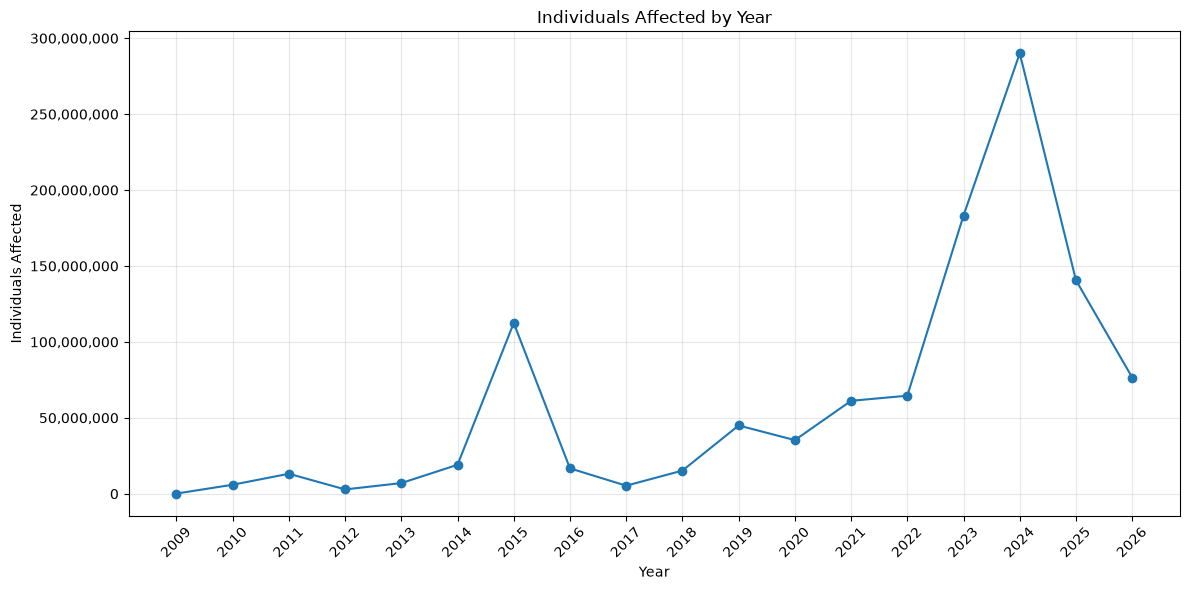

In [34]:
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

plt.figure(figsize=(12, 6))

plt.plot(
    individuals_by_year["breach_year"],
    individuals_by_year["individuals_affected"],
    marker="o"
)

plt.title("Individuals Affected by Year")
plt.xlabel("Year")
plt.ylabel("Individuals Affected")

plt.xticks(
    individuals_by_year["breach_year"],
    rotation=45
)

plt.gca().yaxis.set_major_formatter(
    StrMethodFormatter("{x:,.0f}")
)

plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [35]:
total_by_year = (
    breaches.groupby("breach_year")["individuals_affected"]
    .sum()
)

investigation_by_year = (
    breaches[breaches["record_status"] == "Under Investigation"]
    .groupby("breach_year")["individuals_affected"]
    .sum()
)

individuals_by_year = pd.DataFrame({
    "Total Individuals Affected": total_by_year,
    "Under Investigation": investigation_by_year
}).fillna(0)

individuals_by_year["Under Investigation"] = (
    individuals_by_year["Under Investigation"]
    .replace(0, np.nan)
)

display(individuals_by_year)

,Total Individuals Affected,Under Investigation
breach_year,,
2009,134773.0,NaN
2010,5932276.0,NaN
2011,13162158.0,NaN
2012,2854525.0,NaN
2013,7018839.0,NaN
2014,19073551.0,NaN
2015,112466720.0,NaN
2016,16711004.0,NaN
2017,5314987.0,NaN


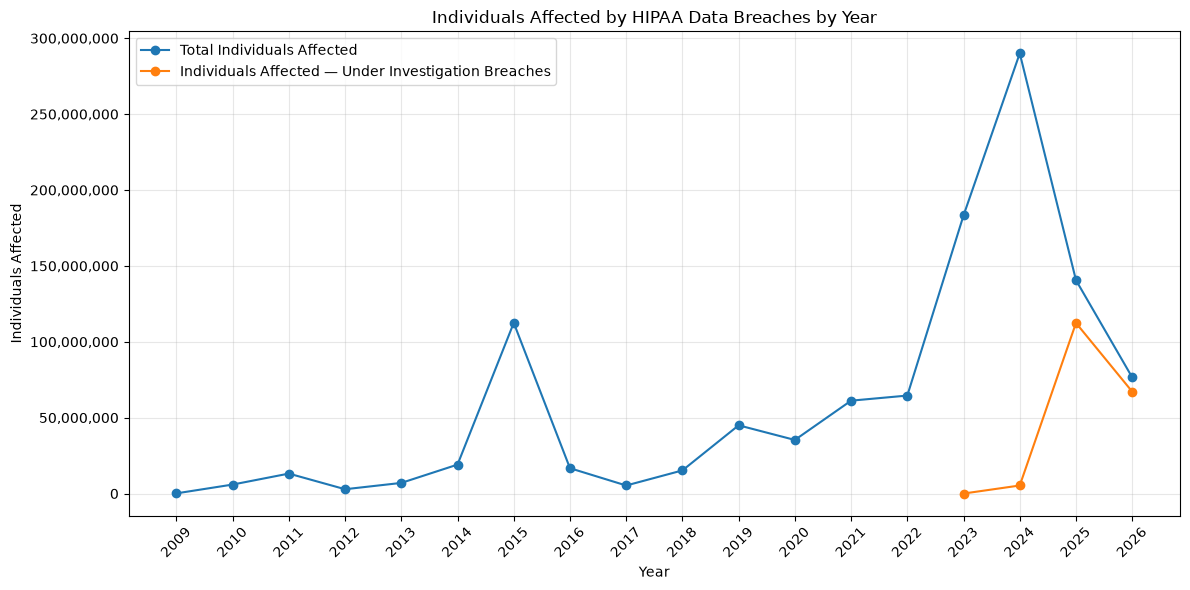

In [36]:
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

plt.figure(figsize=(12, 6))

plt.plot(
    individuals_by_year.index,
    individuals_by_year["Total Individuals Affected"],
    marker="o",
    label="Total Individuals Affected"
)

plt.plot(
    individuals_by_year.index,
    individuals_by_year["Under Investigation"],
    marker="o",
    label="Individuals Affected — Under Investigation Breaches"
)

plt.title("Individuals Affected by HIPAA Data Breaches by Year")
plt.xlabel("Year")
plt.ylabel("Individuals Affected")

plt.xticks(
    individuals_by_year.index,
    rotation=45
)

plt.gca().yaxis.set_major_formatter(
    StrMethodFormatter("{x:,.0f}")
)

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

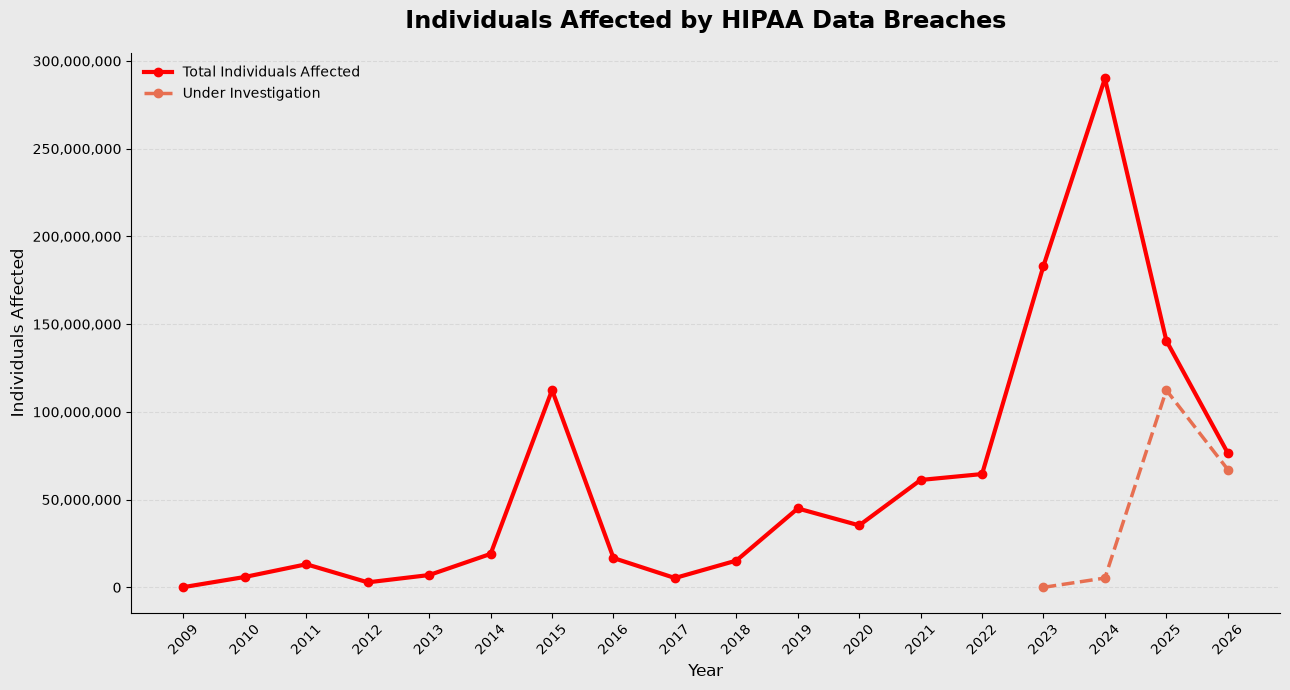

In [37]:
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

individuals_by_year = individuals_by_year.sort_index().copy()

years = individuals_by_year.index
total = individuals_by_year["Total Individuals Affected"]
under_investigation = individuals_by_year["Under Investigation"]

fig, ax = plt.subplots(figsize=(13, 7))

# Light gray background
fig.patch.set_facecolor("#EAEAEA")
ax.set_facecolor("#EAEAEA")

# Total individuals affected — red solid line
ax.plot(
    years,
    total,
    marker="o",
    markersize=6,
    linewidth=3,
    color="red",
    label="Total Individuals Affected"
)

# Under investigation — orange dashed line
ax.plot(
    years,
    under_investigation,
    marker="o",
    markersize=6,
    linewidth=2.5,
    linestyle="--",
    color="#E76F51",
    label="Under Investigation"
)

# Highlight the peak year
peak_year = total.idxmax()
peak_value = total.max()


# Chart styling
ax.set_title(
    "Individuals Affected by HIPAA Data Breaches",
    fontsize=17,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Year", fontsize=12)
ax.set_ylabel("Individuals Affected", fontsize=12)

ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.set_xticks(years)
ax.tick_params(axis="x", rotation=45)

ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(frameon=False, loc="upper left")

plt.tight_layout()
plt.show()

In [38]:
entity_type_counts = (
    breaches["entity_type"]
    .value_counts()
    .reset_index()
)

entity_type_counts.columns = ["entity_type", "breach_count"]

display(entity_type_counts)

,entity_type,breach_count
0,Healthcare Provider,5786
1,Business Associate,1228
2,Health Plan,967
3,Healthcare Clearing House,17


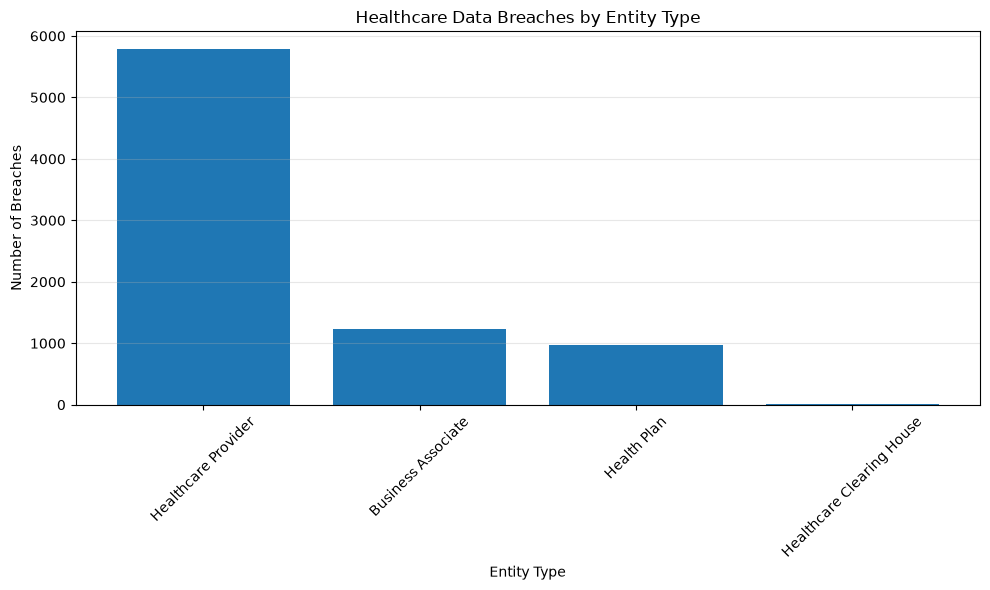

In [39]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.bar(
    entity_type_counts["entity_type"],
    entity_type_counts["breach_count"]
)

plt.title("Healthcare Data Breaches by Entity Type")
plt.xlabel("Entity Type")
plt.ylabel("Number of Breaches")

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [40]:
location_counts = breaches["location_of_breach"].value_counts()

location_percent = location_counts / location_counts.sum() * 100

location_main = location_counts[location_percent >= 2.5]

other_count = location_counts[location_percent < 2.5].sum()

location_pie = location_main.copy()
location_pie["Other"] = other_count

display(location_pie)

location_of_breach
Network Server               3440
Email                        1739
Paper/Films                   914
Laptop                        382
Electronic Medical Record     314
Other                         710
Desktop Computer              203
Name: count, dtype: int64

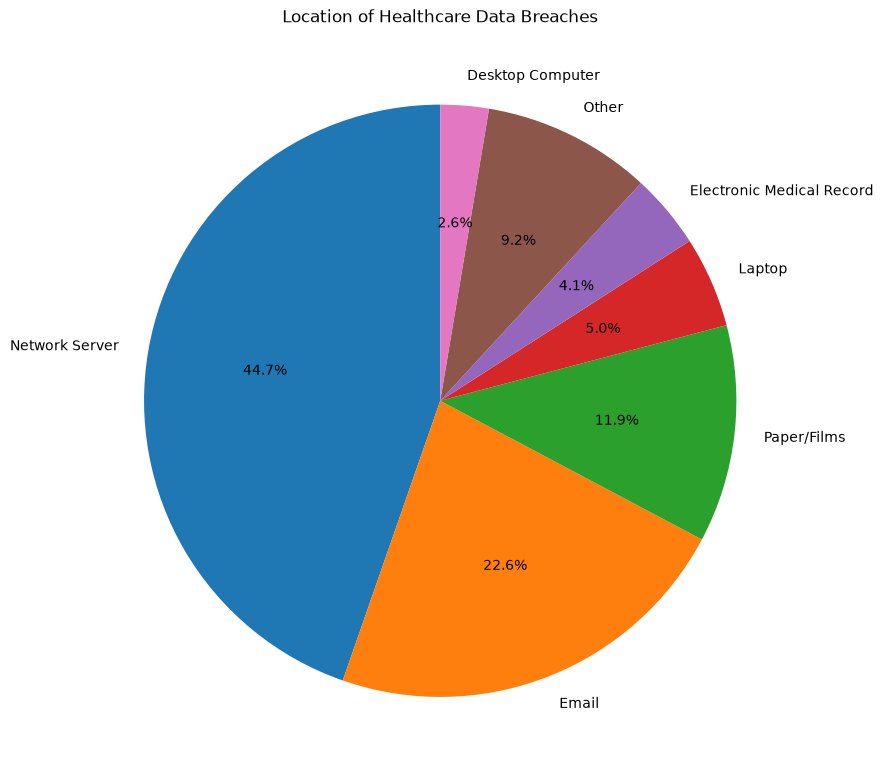

In [41]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 9))

plt.pie(
    location_pie,
    labels=location_pie.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Location of Healthcare Data Breaches")

plt.tight_layout()
plt.show()

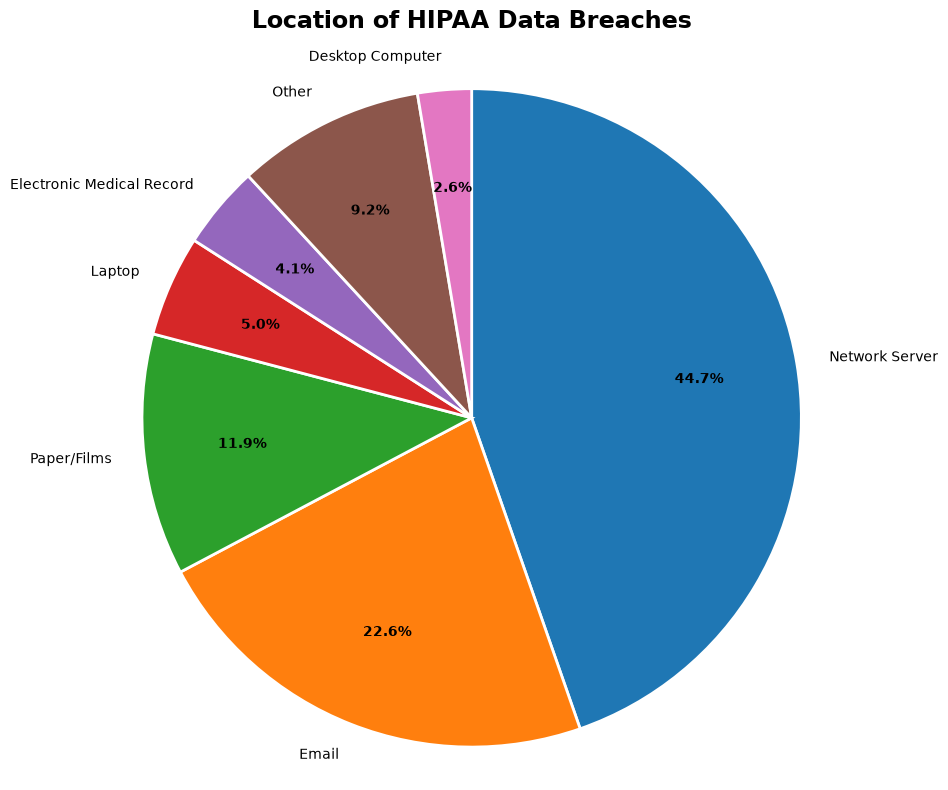

In [42]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 8))

wedges, texts, autotexts = ax.pie(
    location_pie,
    labels=location_pie.index,
    autopct="%1.1f%%",
    startangle=90,
    pctdistance=0.7,
    wedgeprops=dict(edgecolor="white", linewidth=2),
    textprops=dict(fontsize=10),
    counterclock=False
)

for autotext in autotexts:
    autotext.set_fontweight("bold")
    autotext.set_fontsize(10)

ax.set_title(
    "Location of HIPAA Data Breaches",
    fontsize=17,
    fontweight="bold",
    pad=20
)

ax.axis("equal")

plt.tight_layout()
plt.show()

In [43]:
display(location_pie)

location_of_breach
Network Server               3440
Email                        1739
Paper/Films                   914
Laptop                        382
Electronic Medical Record     314
Other                         710
Desktop Computer              203
Name: count, dtype: int64

In [44]:
monthly_breaches = (
    breaches["breach_month"]
    .value_counts()
    .sort_index()
)

month_names = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

monthly_breaches.index = [
    month_names[month - 1]
    for month in monthly_breaches.index
]

display(monthly_breaches)

January      614
February     594
March        729
April        719
May          690
June         695
July         710
August       641
September    681
October      662
November     634
December     634
Name: count, dtype: int64

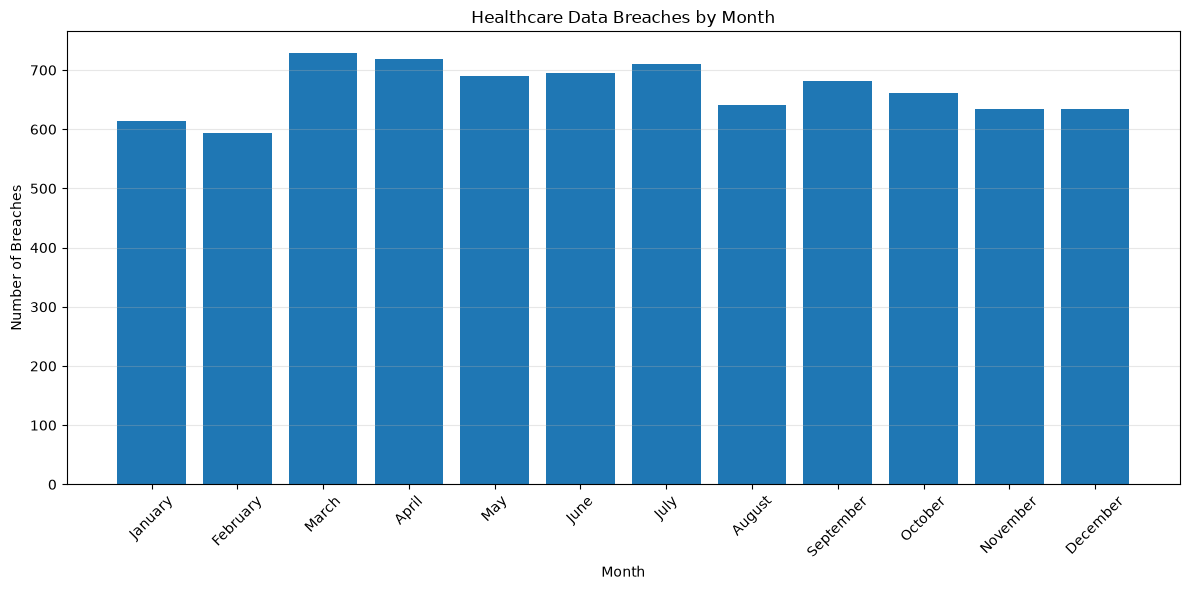

In [45]:
plt.figure(figsize=(12, 6))

plt.bar(
    monthly_breaches.index,
    monthly_breaches.values
)

plt.title("Healthcare Data Breaches by Month")
plt.xlabel("Month")
plt.ylabel("Number of Breaches")

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [46]:
breach_size_counts = (
    breaches["breach_size_category"]
    .value_counts()
    .reindex([
        "500-1,000",
        "1,001-10,000",
        "10,001-100,000",
        "100,001-1,000,000",
        "1,000,000-10,000,000",
        "10,000,001+"
    ])
)

display(breach_size_counts)

breach_size_category
500-1,000               1570
1,001-10,000            3674
10,001-100,000          1946
100,001-1,000,000        661
1,000,000-10,000,000     141
10,000,001+               11
Name: count, dtype: int64

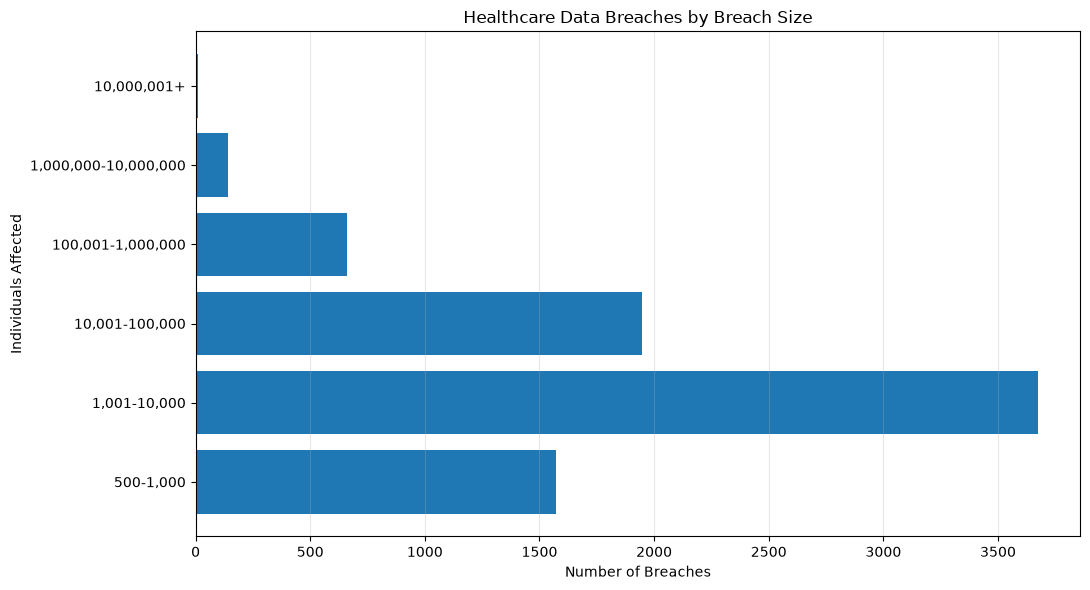

In [47]:
plt.figure(figsize=(11, 6))

plt.barh(
    breach_size_counts.index,
    breach_size_counts.values
)

plt.title("Healthcare Data Breaches by Breach Size")
plt.xlabel("Number of Breaches")
plt.ylabel("Individuals Affected")

plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

,breach_year,Number of Breaches
0,2009,18
1,2010,199
2,2011,200
3,2012,218
4,2013,276
5,2014,314
6,2015,270
7,2016,328
8,2017,358
9,2018,369


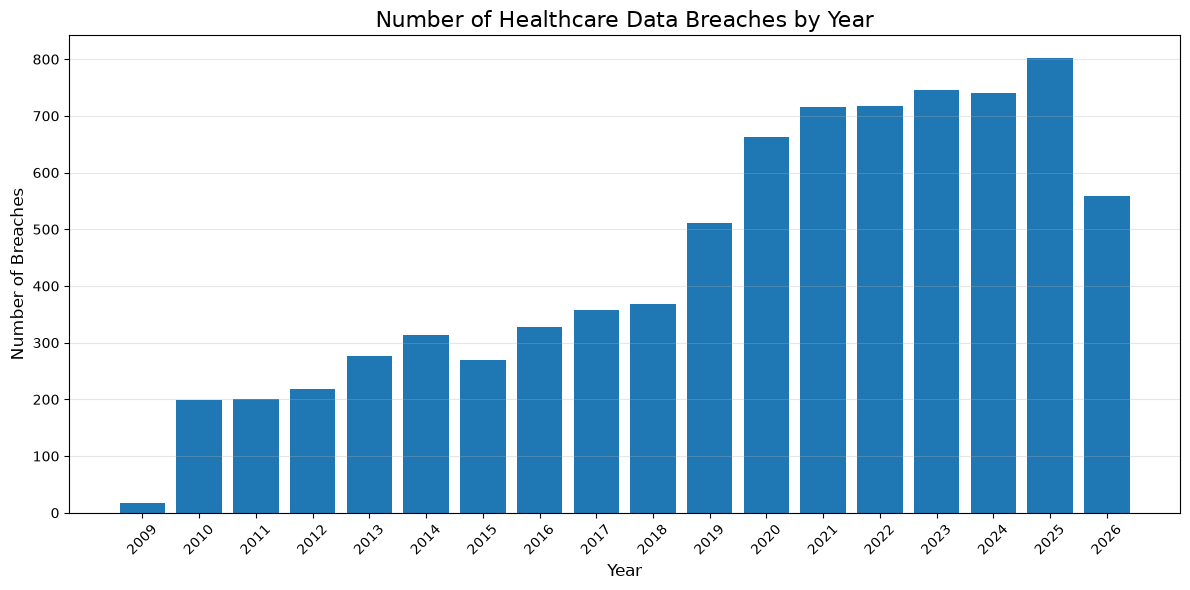

In [48]:

import matplotlib.pyplot as plt

breaches_by_year = (
    breaches.groupby("breach_year")
    .size()
    .reset_index(name="Number of Breaches")
)

display(breaches_by_year)

plt.figure(figsize=(12, 6))

plt.bar(
    breaches_by_year["breach_year"],
    breaches_by_year["Number of Breaches"]
)

plt.title("Number of Healthcare Data Breaches by Year", fontsize=16)
plt.xlabel("Year", fontsize=12)
plt.ylabel("Number of Breaches", fontsize=12)

plt.xticks(
    breaches_by_year["breach_year"],
    rotation=45
)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

C:\Users\joshs\AppData\Local\Temp\ipykernel_29348\2310188649.py:39: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(frameon=False)


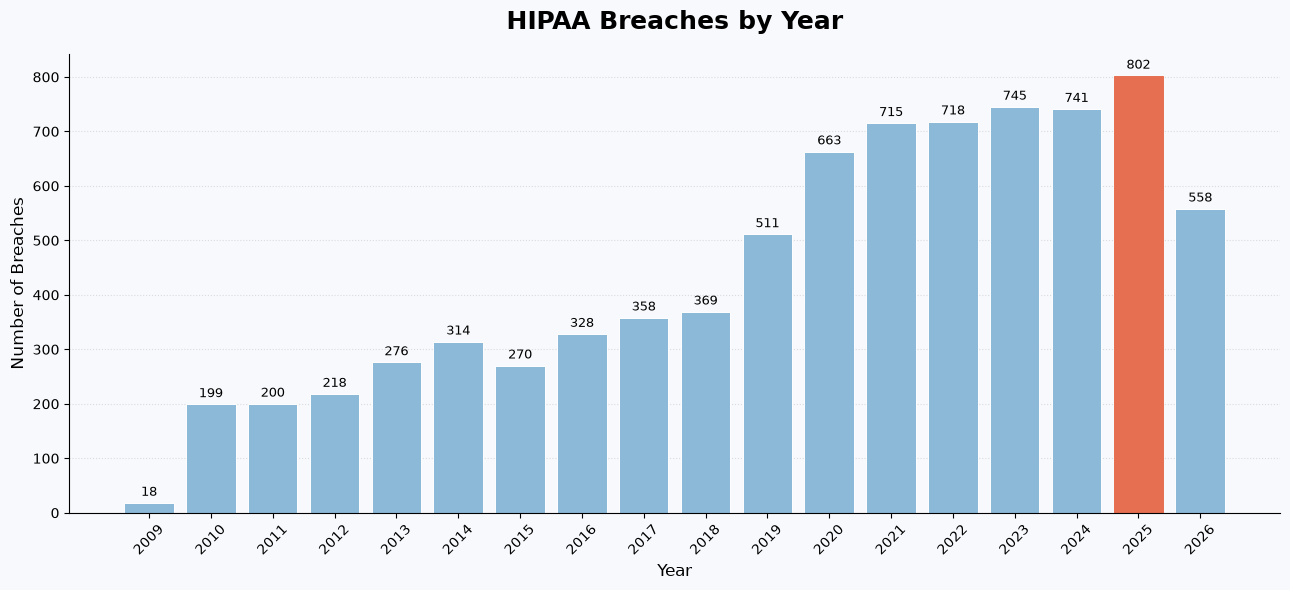

In [49]:

breaches_by_year = breaches_by_year.sort_values("breach_year").copy()

years = breaches_by_year["breach_year"].astype(str)
counts = breaches_by_year["Number of Breaches"]

peak_index = counts.idxmax()
peak_position = breaches_by_year.index.get_loc(peak_index)

fig, ax = plt.subplots(figsize=(13, 6))

bars = ax.bar(
    years,
    counts,
    color="#8DB9D8",
    edgecolor="white",
    linewidth=0.7
)

bars[peak_position].set_color("#E76F51")

ax.bar_label(bars, padding=3, fontsize=9)

ax.set_title(
    "HIPAA Breaches by Year",
    fontsize=18,
    fontweight="bold",
    pad=18
)
ax.set_xlabel("Year", fontsize=12)
ax.set_ylabel("Number of Breaches", fontsize=12)

ax.set_facecolor("#F7F9FC")
fig.patch.set_facecolor("#F7F9FC")

ax.grid(axis="y", linestyle=":", alpha=0.4)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(frameon=False)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

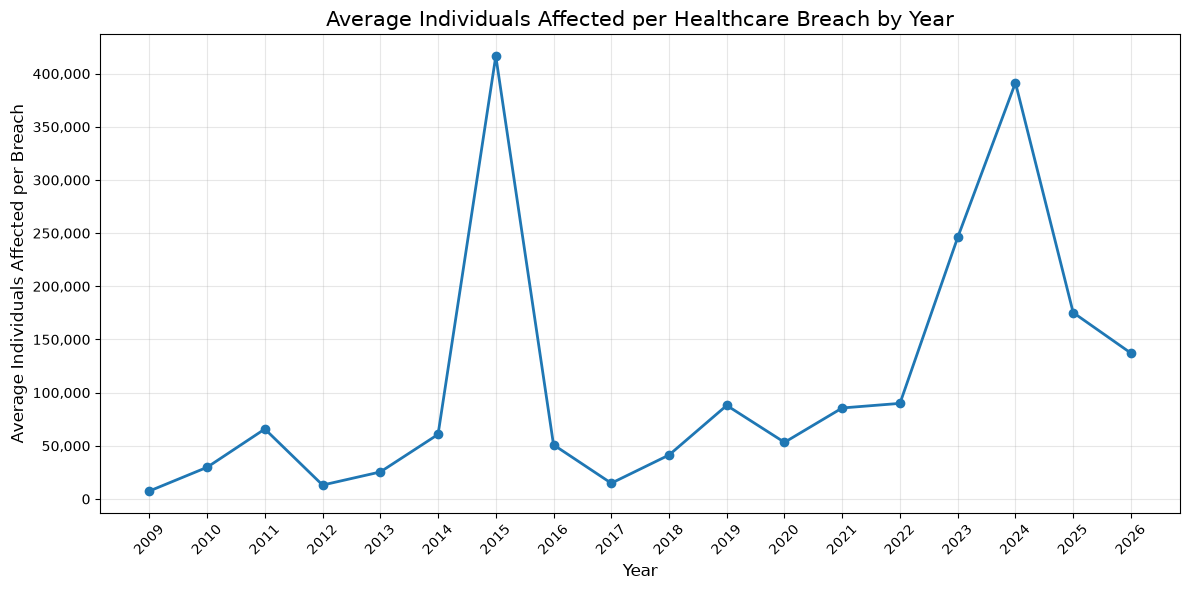

In [50]:
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

avg_breach_by_year = (
    breaches.groupby("breach_year")["individuals_affected"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(12, 6))

plt.plot(
    avg_breach_by_year["breach_year"],
    avg_breach_by_year["individuals_affected"],
    marker="o",
    linewidth=2
)

plt.title("Average Individuals Affected per Healthcare Breach by Year", fontsize=15)
plt.xlabel("Year", fontsize=12)
plt.ylabel("Average Individuals Affected per Breach", fontsize=12)

plt.xticks(avg_breach_by_year["breach_year"], rotation=45)
plt.gca().yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

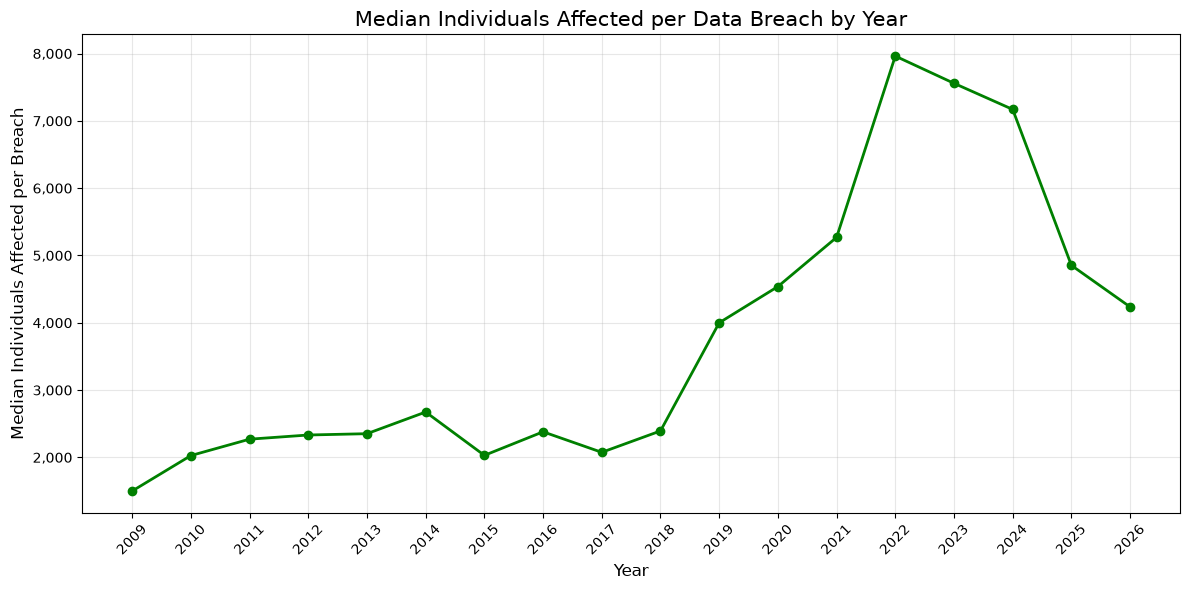

In [51]:
median_breach_by_year = (
    breaches.groupby("breach_year")["individuals_affected"]
    .median()
    .reset_index()
)

plt.figure(figsize=(12, 6))

plt.plot(
    median_breach_by_year["breach_year"],
    median_breach_by_year["individuals_affected"],
    marker="o",
    linewidth=2,
    color="green"
)

plt.title("Median Individuals Affected per Data Breach by Year", fontsize=15)
plt.xlabel("Year", fontsize=12)
plt.ylabel("Median Individuals Affected per Breach", fontsize=12)
plt.xticks(median_breach_by_year["breach_year"], rotation=45)
plt.gca().yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

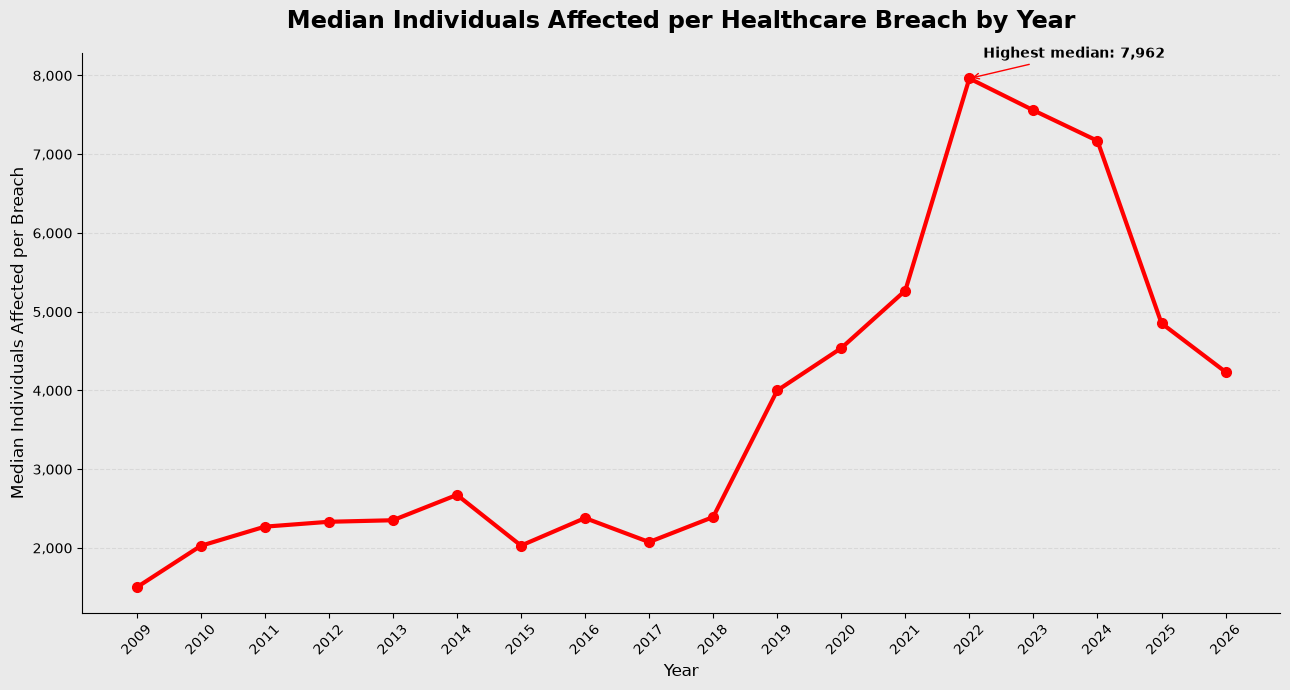

In [52]:
from matplotlib.ticker import StrMethodFormatter

median_breach_by_year = (
    breaches.groupby("breach_year")["individuals_affected"]
    .median()
    .reset_index()
    .sort_values("breach_year")
)

fig, ax = plt.subplots(figsize=(13, 7))

fig.patch.set_facecolor("#EAEAEA")
ax.set_facecolor("#EAEAEA")

ax.plot(
    median_breach_by_year["breach_year"],
    median_breach_by_year["individuals_affected"],
    marker="o",
    markersize=7,
    linewidth=3,
    color="red"
)


peak = median_breach_by_year.loc[
    median_breach_by_year["individuals_affected"].idxmax()
]

ax.annotate(
    f"Highest median: {peak['individuals_affected']:,.0f}",
    xy=(peak["breach_year"], peak["individuals_affected"]),
    xytext=(10, 15),
    textcoords="offset points",
    fontsize=10,
    fontweight="bold",
    arrowprops=dict(arrowstyle="->", color="red")
)

ax.set_title(
    "Median Individuals Affected per Healthcare Breach by Year",
    fontsize=17,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Year", fontsize=12)
ax.set_ylabel("Median Individuals Affected per Breach", fontsize=12)

ax.set_xticks(median_breach_by_year["breach_year"])
ax.tick_params(axis="x", rotation=45)
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))

ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

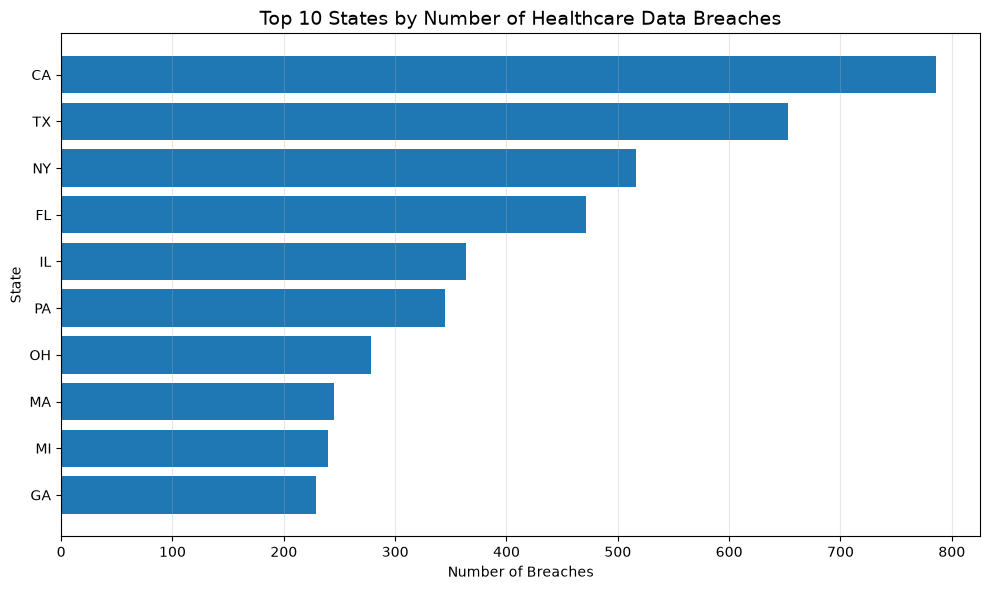

In [53]:
state_counts = (
    breaches["state"]
    .dropna()
    .value_counts()
    .head(10)
    .sort_values(ascending=True)
)

plt.figure(figsize=(10, 6))

plt.barh(state_counts.index, state_counts.values)

plt.title("Top 10 States by Number of Healthcare Data Breaches", fontsize=14)
plt.xlabel("Number of Breaches")
plt.ylabel("State")

plt.gca().xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

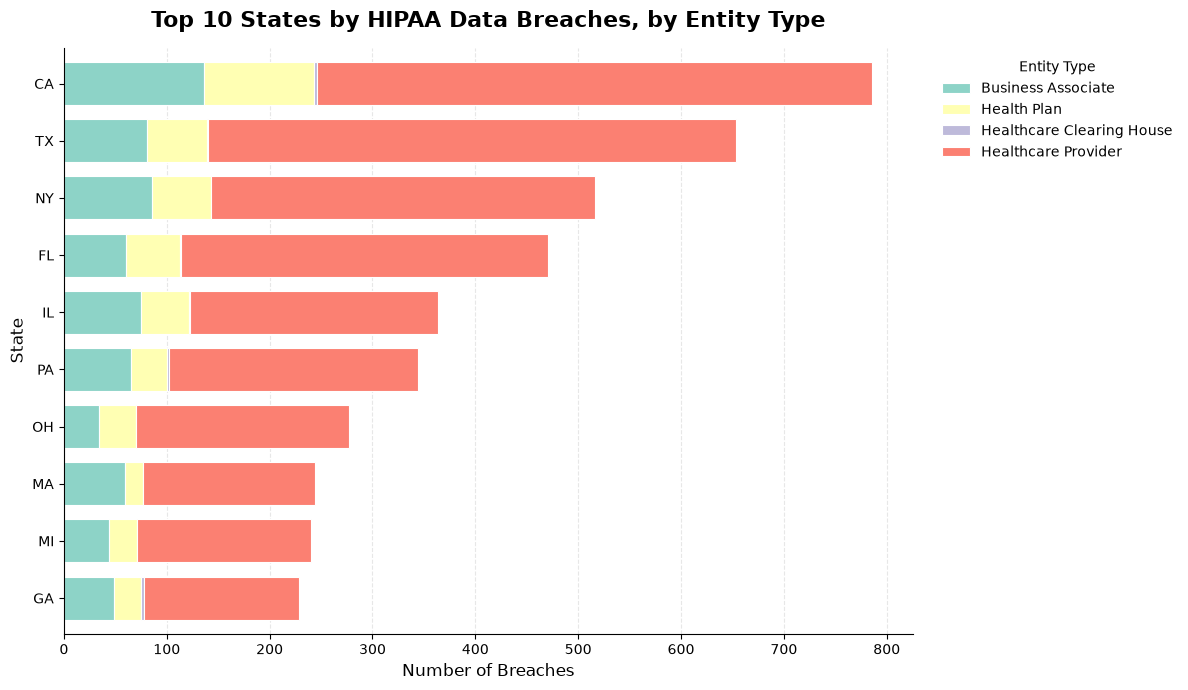

In [54]:
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

top_states = breaches["state"].dropna().value_counts().head(10).index

state_counts = (
    breaches[breaches["state"].isin(top_states)]
    .groupby(["state", "entity_type"])
    .size()
    .unstack(fill_value=0)
)

state_counts = state_counts.loc[
    state_counts.sum(axis=1).sort_values().index
]

fig, ax = plt.subplots(figsize=(12, 7))

colors = plt.cm.Set3.colors

state_counts.plot(
    kind="barh",
    stacked=True,
    ax=ax,
    color=colors[:len(state_counts.columns)],
    edgecolor="white",
    linewidth=0.8,
    width=0.75
)

ax.set_title(
    "Top 10 States by HIPAA Data Breaches, by Entity Type",
    fontsize=16,
    fontweight="bold",
    pad=15
)
ax.set_xlabel("Number of Breaches", fontsize=12)
ax.set_ylabel("State", fontsize=12)

ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(
    title="Entity Type",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False
)

plt.tight_layout()
plt.show()

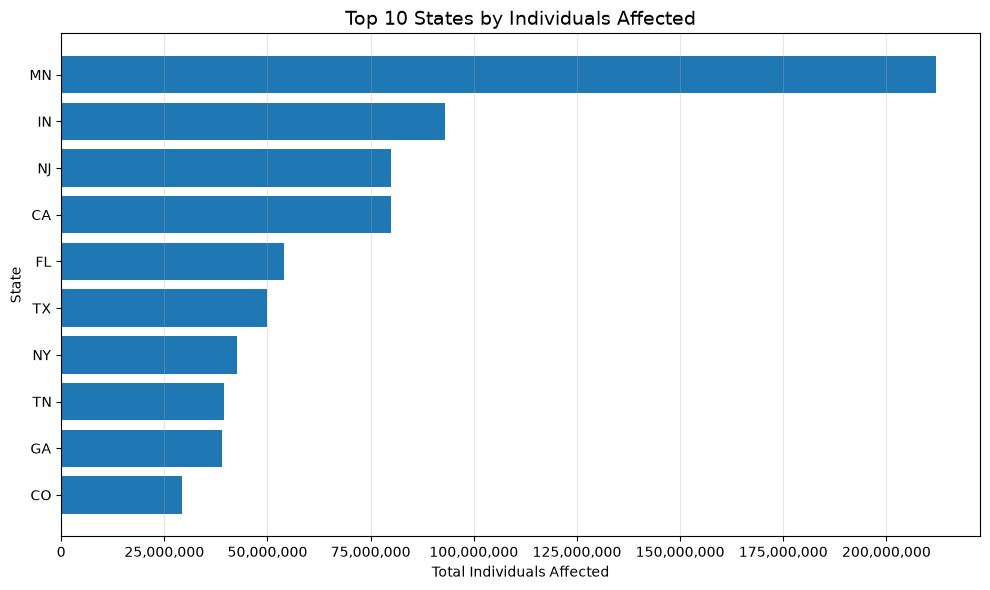

In [55]:
state_affected = (
    breaches.dropna(subset=["state"])
    .groupby("state")["individuals_affected"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .sort_values(ascending=True)
)

plt.figure(figsize=(10, 6))

plt.barh(state_affected.index, state_affected.values)

plt.title("Top 10 States by Individuals Affected", fontsize=14)
plt.xlabel("Total Individuals Affected")
plt.ylabel("State")

plt.gca().xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

In [56]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import StrMethodFormatter

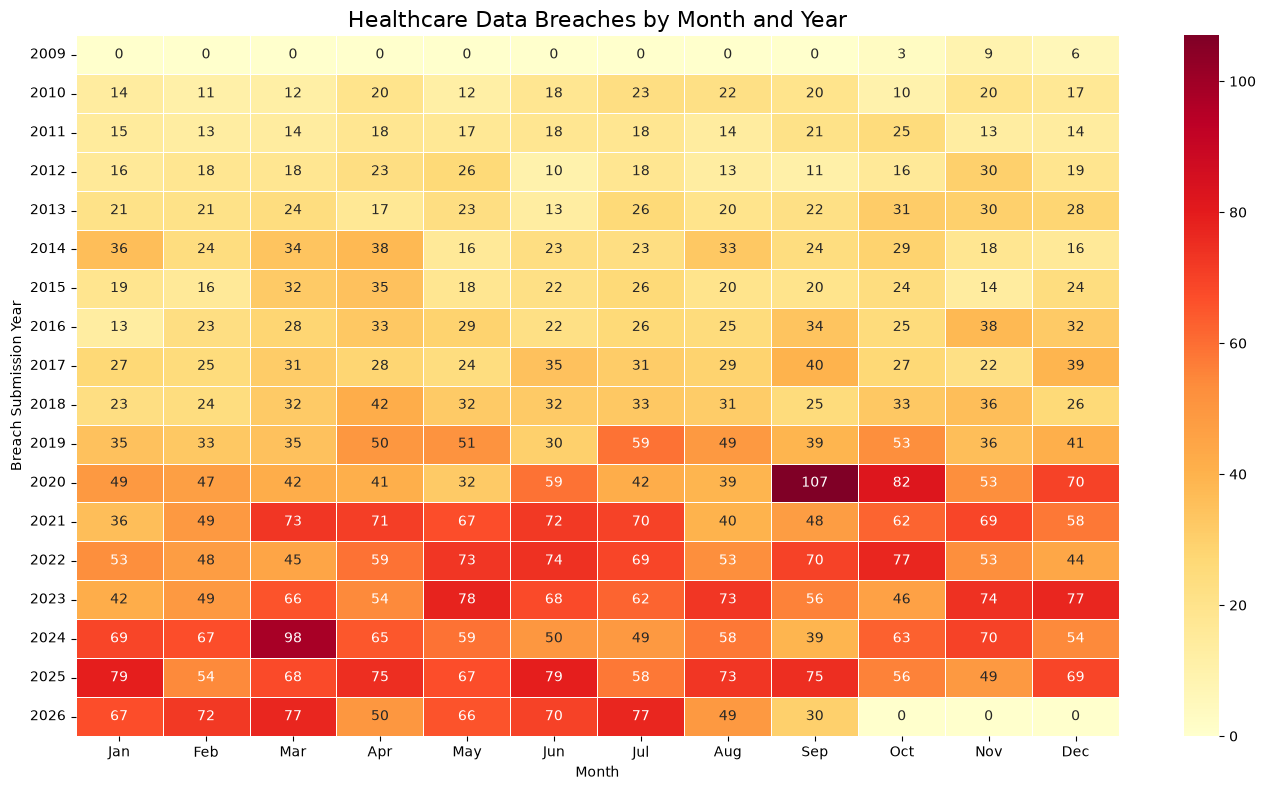

In [57]:
month_year = pd.crosstab(
    breaches["breach_year"],
    breaches["breach_month"]
)

month_year = month_year.reindex(columns=range(1, 13), fill_value=0)

month_names = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]
month_year.columns = month_names

plt.figure(figsize=(14, 8))
sns.heatmap(
    month_year,
    cmap="YlOrRd",
    annot=True,
    fmt="d",
    linewidths=0.5
)

plt.title("Healthcare Data Breaches by Month and Year", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Breach Submission Year")
plt.tight_layout()
plt.show()

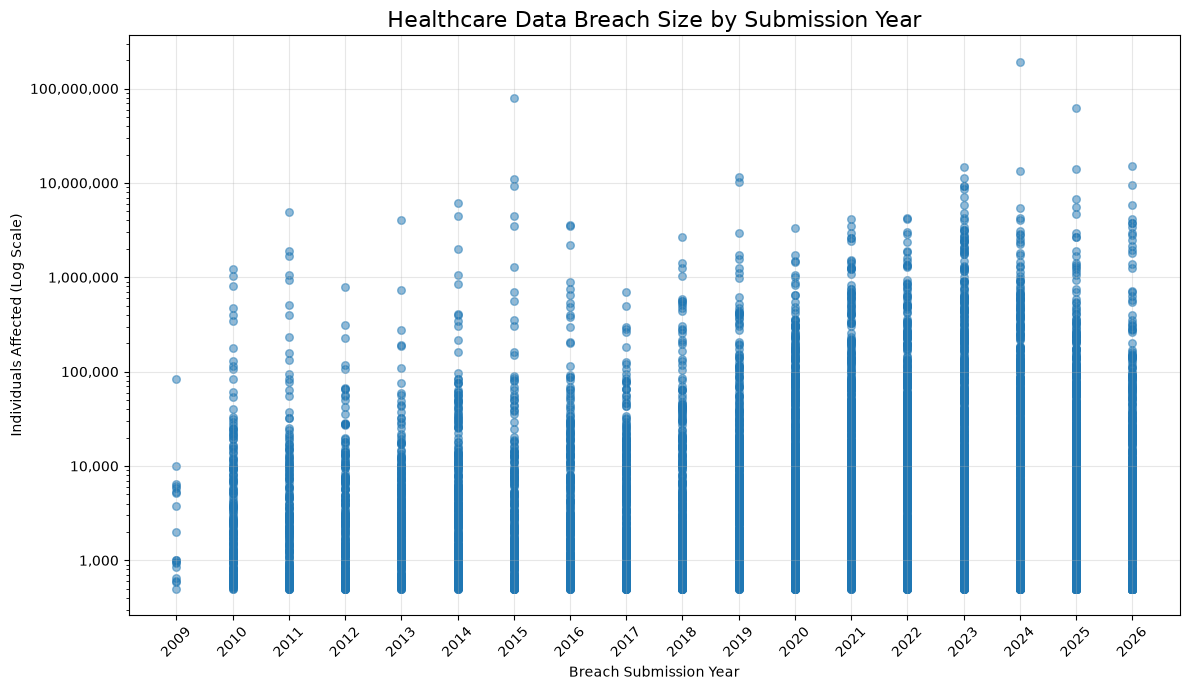

In [58]:
scatter_data = breaches.dropna(
    subset=["breach_year", "individuals_affected"]
).copy()

scatter_data = scatter_data[
    scatter_data["individuals_affected"] > 0
]

plt.figure(figsize=(12, 7))

plt.scatter(
    scatter_data["breach_year"],
    scatter_data["individuals_affected"],
    alpha=0.5,
    s=30
)

plt.yscale("log")

plt.title("Healthcare Data Breach Size by Submission Year", fontsize=16)
plt.xlabel("Breach Submission Year")
plt.ylabel("Individuals Affected (Log Scale)")

years = sorted(scatter_data["breach_year"].unique())
plt.xticks(years, rotation=45)

plt.gca().yaxis.set_major_formatter(
    StrMethodFormatter("{x:,.0f}")
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

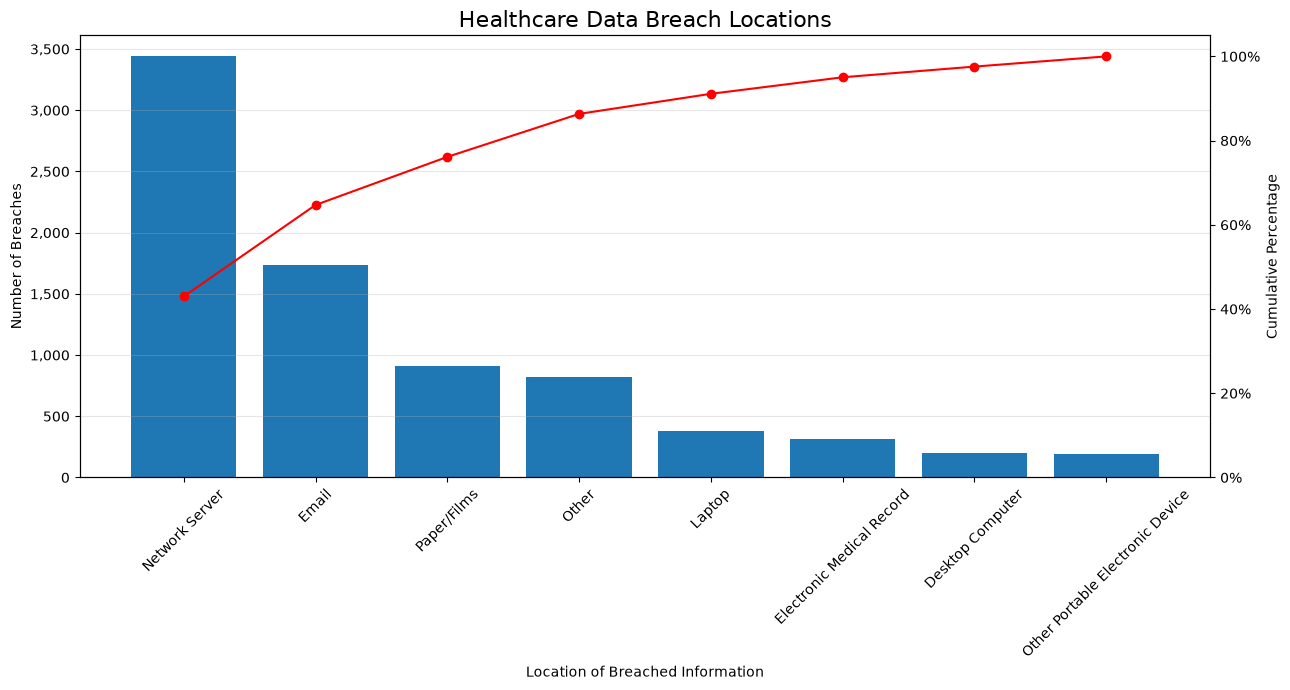

In [59]:
location_counts = breaches["location_of_breach"].dropna().value_counts()

location_percent = location_counts / location_counts.sum() * 100

small_locations = location_percent[location_percent < 2].index

breaches["location_grouped_2pct"] = breaches["location_of_breach"].replace(
    small_locations, "Other"
)


location_counts = (
    breaches["location_grouped_2pct"]
    .dropna()
    .value_counts()
    .sort_values(ascending=False)
)

location_cumulative_percent = (
    location_counts.cumsum() / location_counts.sum() * 100
)

fig, ax1 = plt.subplots(figsize=(13, 7))

ax1.bar(location_counts.index, location_counts.values)
ax1.set_xlabel("Location of Breached Information")
ax1.set_ylabel("Number of Breaches")
ax1.set_title("Healthcare Data Breach Locations", fontsize=16)
ax1.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax1.tick_params(axis="x", rotation=45)
ax1.grid(axis="y", alpha=0.3)

ax2 = ax1.twinx()
ax2.plot(
    location_counts.index,
    location_cumulative_percent.values,
    marker="o",
    color="red"
)
ax2.set_ylabel("Cumulative Percentage")
ax2.set_ylim(0, 105)
ax2.yaxis.set_major_formatter(StrMethodFormatter("{x:.0f}%"))

plt.tight_layout()
plt.show()


In [60]:
state_breaches = (
    breaches["state"]
    .value_counts()
    .reset_index()
)

state_breaches.columns = ["state", "breach_count"]

display(state_breaches)

,state,breach_count
0,CA,786
1,TX,653
2,NY,516
3,FL,471
4,IL,364
5,PA,345
6,OH,278
7,MA,245
8,MI,240
9,GA,229


In [61]:
%pip install plotly
%pip install --upgrade nbformat

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [62]:
import plotly.express as px

fig = px.choropleth(
    state_breaches,
    locations="state",
    locationmode="USA-states",
    color="breach_count",
    scope="usa",
    color_continuous_scale="Blues",
    labels={"breach_count": "Number of Breaches"},
    title="Healthcare Data Breaches by State",
    width=850,
    height=750
)

fig.update_layout(
    autosize=False,
    width=850,
    height=750,
    margin=dict(l=20, r=20, t=70, b=20),
    title=dict(
        x=0.5,
        xanchor="center",
        font=dict(size=20)
    ),
    coloraxis_colorbar=dict(
        title="Number of<br>Breaches",
        thickness=15,
        len=0.7
    )
)

fig.show()

In [63]:
state_affected = (
    breaches.dropna(subset=["state"])
    .groupby("state")["individuals_affected"]
    .sum()
    .reset_index()
)

state_affected.columns = ["state", "individuals_affected"]

In [64]:
fig = px.choropleth(
    state_affected,
    locations="state",
    locationmode="USA-states",
    color="individuals_affected",
    scope="usa",
    color_continuous_scale="Reds",
    labels={"individuals_affected": "Individuals Affected"},
    title="Individuals Affected by Healthcare Data Breaches by State"
)

fig.show()

In [65]:
state_affected = (
    breaches.dropna(subset=["state", "individuals_affected"])
    .groupby("state")["individuals_affected"]
    .median()
    .reset_index()
)

state_affected.columns = ["state", "individuals_affected"]

fig = px.choropleth(
    state_affected,
    locations="state",
    locationmode="USA-states",
    color="individuals_affected",
    scope="usa",
    color_continuous_scale="Reds",
    labels={"individuals_affected": "Median Individuals Affected"},
    title="Median Individuals Affected per Healthcare Data Breach by State"
)

fig.show() 

In [66]:
state_affected = (
    breaches.dropna(subset=["state", "individuals_affected"])
    .groupby("state")["individuals_affected"]
    .median()
    .reset_index()
)

state_affected.columns = ["state", "individuals_affected"]

fig = px.choropleth(
    state_affected,
    locations="state",
    locationmode="USA-states",
    color="individuals_affected",
    scope="usa",
    color_continuous_scale="Reds",
    labels={"individuals_affected": "Median Individuals Affected"},
    title="Median Individuals Affected per Healthcare Data Breach by State",
    width=850,
    height=750
)

fig.update_layout(
    autosize=False,
    width=850,
    height=750,
    margin=dict(l=20, r=20, t=75, b=20),
    title=dict(
        x=0.5,
        xanchor="center",
        font=dict(size=18)
    ),
    coloraxis_colorbar=dict(
        title="Median Individuals<br>Affected",
        thickness=15,
        len=0.7
    )
)

fig.show()

In [67]:
%pip install scipy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [68]:
from scipy.stats import pearsonr, spearmanr
import numpy as np
import pandas as pd

data = breaches[
    ["breach_year", "individuals_affected"]
].dropna().copy()

data = data[data["individuals_affected"] >= 0]

data["log_individuals_affected"] = np.log1p(
    data["individuals_affected"]
)

pearson_r, pearson_p = pearsonr(
    data["breach_year"],
    data["log_individuals_affected"]
)

spearman_r, spearman_p = spearmanr(
    data["breach_year"],
    data["individuals_affected"]
)

print("Pearson correlation:", round(pearson_r, 3))
print("Pearson p-value:", pearson_p)

print("Spearman correlation:", round(spearman_r, 3))
print("Spearman p-value:", spearman_p)

Pearson correlation: 0.187
Pearson p-value: 7.406702015242431e-64
Spearman correlation: 0.167
Spearman p-value: 3.428027600532847e-51


In [69]:
from scipy.stats import kruskal

data = breaches.dropna(
    subset=["entity_type", "individuals_affected"]
)

groups = [
    group["individuals_affected"].values
    for _, group in data.groupby("entity_type")
    if len(group) > 0
]

statistic, p_value = kruskal(*groups)

print("Kruskal-Wallis statistic:", round(statistic, 3))
print("P-value:", p_value)

Kruskal-Wallis statistic: 56.605
P-value: 3.1197828428027527e-12


In [70]:
from scipy.stats import chi2_contingency

table = pd.crosstab(
    breaches["breach_type"],
    breaches["location_of_breach"]
)

chi2, p_value, degrees_freedom, expected = chi2_contingency(table)

n = table.to_numpy().sum()
min_dimension = min(table.shape) - 1
cramers_v = np.sqrt(chi2 / (n * min_dimension))

print("Chi-square statistic:", round(chi2, 3))
print("P-value:", p_value)
print("Cramer's V:", round(cramers_v, 3))

Chi-square statistic: 24107.086
P-value: 0.0
Cramer's V: 0.322


In [71]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

financials = pd.read_csv(r"C:\Users\joshs\Downloads\nonprofit-health-org-finances.csv")

financials.head()

,ein,org_name,state,fiscal_year,total_revenue,total_expenses,highest_exec_compensation
0,941340523,Kaiser Foundation Health Plan Inc,CA,2023,7.510131e+10,7.435600e+10,NaN
1,941105628,Kaiser Foundation Hospitals,CA,2023,3.278736e+10,3.065070e+10,12835.0
2,900656139,Mass General Brigham Incorporated And Affiliat...,MA,2023,2.273322e+10,2.158441e+10,2841349.0
3,383952644,Mayo Clinic Group Return,MN,2023,1.397074e+10,1.377896e+10,4309705.0
4,133783732,Healthfirst Phsp Inc,NY,2023,1.208568e+10,1.192440e+10,NaN


In [72]:
financials.columns = financials.columns.str.strip()

financials["org_name"] = financials["org_name"].str.strip()
financials["state"] = financials["state"].str.strip().str.upper()

financials = financials.dropna(subset=["org_name"])

financials.info()

<class 'pandas.DataFrame'>
RangeIndex: 18829 entries, 0 to 18828
Data columns (total 7 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   ein                        18829 non-null  int64  
 1   org_name                   18829 non-null  str    
 2   state                      18821 non-null  str    
 3   fiscal_year                18829 non-null  int64  
 4   total_revenue              18788 non-null  float64
 5   total_expenses             18739 non-null  float64
 6   highest_exec_compensation  1057 non-null   float64
dtypes: float64(3), int64(2), str(2)
memory usage: 1.0 MB


In [73]:
financial_columns = [
    "fiscal_year",
    "total_revenue",
    "total_expenses",
    "highest_exec_compensation"
]

for column in financial_columns:
    financials[column] = pd.to_numeric(
        financials[column],
        errors="coerce"
    )

financials[financial_columns].isna().sum()

fiscal_year                      0
total_revenue                   41
total_expenses                  90
highest_exec_compensation    17772
dtype: int64

In [74]:
print("Exact duplicate rows:", financials.duplicated().sum())

print(
    "Repeated organization-year rows:",
    financials.duplicated(
        subset=["ein", "fiscal_year"]
    ).sum()
)

print(financials[financial_columns].describe())

Exact duplicate rows: 0
Repeated organization-year rows: 0
        fiscal_year  total_revenue  total_expenses  highest_exec_compensation
count  18829.000000   1.878800e+04    1.873900e+04               1.057000e+03
mean    2022.910139   8.213913e+07    8.016898e+07               6.585822e+05
std        0.912986   7.656720e+08    7.480596e+08               1.099149e+06
min     2011.000000  -5.092579e+07    1.000000e+00               0.000000e+00
25%     2023.000000   1.945008e+05    1.812185e+05               2.372120e+05
50%     2023.000000   8.379730e+05    7.847760e+05               3.684700e+05
75%     2023.000000   8.029355e+06    7.918656e+06               7.158740e+05
max     2024.000000   7.510131e+10    7.435600e+10               1.636163e+07


In [75]:
financials["net_revenue_after_expenses"] = (
    financials["total_revenue"] -
    financials["total_expenses"]
)

financials["operating_margin_pct"] = np.where(
    financials["total_revenue"] > 0,
    (
        financials["net_revenue_after_expenses"] /
        financials["total_revenue"]
    ) * 100,
    np.nan
)

financials[
    [
        "org_name",
        "fiscal_year",
        "total_revenue",
        "total_expenses",
        "net_revenue_after_expenses",
        "operating_margin_pct"
    ]
].head(10)

,org_name,fiscal_year,total_revenue,total_expenses,net_revenue_after_expenses,operating_margin_pct
0,Kaiser Foundation Health Plan Inc,2023,7.510131e+10,7.435600e+10,7.453029e+08,0.992397
1,Kaiser Foundation Hospitals,2023,3.278736e+10,3.065070e+10,2.136665e+09,6.516733
2,Mass General Brigham Incorporated And Affiliat...,2023,2.273322e+10,2.158441e+10,1.148816e+09,5.053470
3,Mayo Clinic Group Return,2023,1.397074e+10,1.377896e+10,1.917848e+08,1.372760
4,Healthfirst Phsp Inc,2023,1.208568e+10,1.192440e+10,1.612749e+08,1.334430
5,Corewell Health,2023,1.037425e+10,1.022959e+10,1.446614e+08,1.394428
6,The New York And Presbyterian Hospital,2023,1.025451e+10,9.755790e+09,4.987218e+08,4.863437
7,Dignity Health,2023,9.914543e+09,1.012669e+10,-2.121440e+08,-2.139725
8,Providence Health & Services Washington,2023,9.778289e+09,1.012214e+10,-3.438501e+08,-3.516465
9,Ihc Health Services Inc,2023,9.638579e+09,8.793797e+09,8.447813e+08,8.764584


In [76]:
financials.columns = (
    financials.columns
    .str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

numeric_cols = [
    "fiscal_year",
    "total_revenue",
    "total_expenses",
    "highest_exec_compensation"
]

for col in numeric_cols:
    if col in financials.columns:
        financials[col] = pd.to_numeric(
            financials[col], errors="coerce"
        )

financials["net_revenue_after_expenses"] = (
    financials["total_revenue"] - financials["total_expenses"]
)

financials["operating_margin_pct"] = np.where(
    financials["total_revenue"] > 0,
    financials["net_revenue_after_expenses"]
    / financials["total_revenue"] * 100,
    np.nan
)

financials = financials.dropna(subset=["org_name"]).copy()

print("Dataset shape:", financials.shape)
print("Missing values:")
print(financials[
    ["fiscal_year", "total_revenue", "total_expenses",
     "net_revenue_after_expenses", "operating_margin_pct"]
].isna().sum())

Dataset shape: (18829, 9)
Missing values:
fiscal_year                     0
total_revenue                  41
total_expenses                 90
net_revenue_after_expenses     96
operating_margin_pct          134
dtype: int64


C:\Users\joshs\AppData\Local\Temp\ipykernel_29348\2289462728.py:32: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


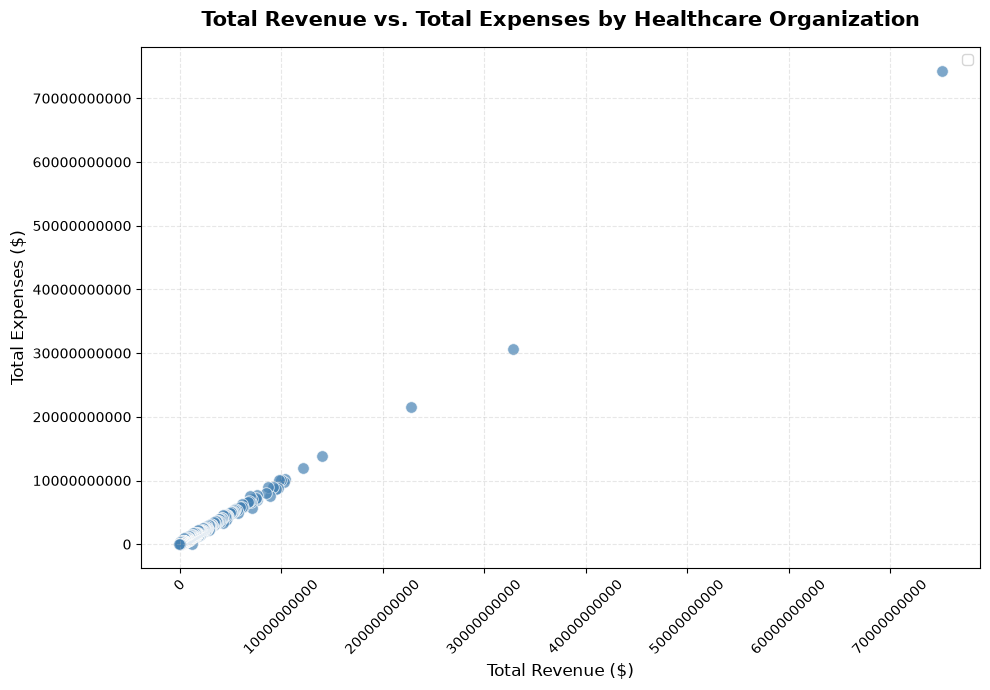

In [77]:
import matplotlib.pyplot as plt
import seaborn as sns

plot_data = financials.dropna(
    subset=["total_revenue", "total_expenses"]
)

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=plot_data,
    x="total_revenue",
    y="total_expenses",
    color="steelblue",
    alpha=0.7,
    s=70
)


plt.title(
    "Total Revenue vs. Total Expenses by Healthcare Organization",
    fontsize=15,
    fontweight="bold",
    pad=15
)
plt.xlabel("Total Revenue ($)", fontsize=12)
plt.ylabel("Total Expenses ($)", fontsize=12)

plt.ticklabel_format(style="plain", axis="both", useOffset=False)
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [78]:
print(
    "Duplicate organization-year rows:",
    financials.duplicated(
        subset=["org_name", "fiscal_year"]
    ).sum()
)

Duplicate organization-year rows: 160


In [79]:
missing_financials = financials[
    financials["total_revenue"].isna()
    | financials["total_expenses"].isna()
]

print("Rows missing revenue or expenses:", len(missing_financials))

missing_financials[
    ["org_name", "fiscal_year", "total_revenue", "total_expenses"]
].head(15)

Rows missing revenue or expenses: 96


,org_name,fiscal_year,total_revenue,total_expenses
1796,Nebraska Medicine,2023,63024916.0,NaN
4217,National Abortion Federation Inc,2023,10607954.0,NaN
4391,Florida Community Health Network Corp,2023,9604890.0,NaN
4413,Faulk Endowment,2023,9459864.0,NaN
5885,Mega Care Inc,2023,4147842.0,NaN
7117,Sj Management Company Of Syracuse Inc,2023,2155303.0,NaN
7967,Yellowstone Behavioral Health Foundation Inc,2023,1473385.0,NaN
11499,Mental Health America Of Lancaster County Foun...,2023,422939.0,NaN
11688,Kindle Hill Foundation Charity,2023,400735.0,NaN
11932,Changing Smiles Pediatric Dentistry,2023,372000.0,NaN


In [80]:
print("Rows before cleaning:", len(financials))

Rows before cleaning: 18829


In [81]:
financials = financials.dropna(
    subset=["total_revenue", "total_expenses", "operating_margin_pct"]
).copy()

In [82]:

state_revenue = (
    financials
    .groupby("state", as_index=False)
    .agg(
        avg_net_revenue=("net_revenue_after_expenses", "mean"),
        organization_count=("org_name", "nunique")
    )
)

state_revenue = state_revenue.dropna(
    subset=["state", "avg_net_revenue"]
)

fig = px.choropleth(
    state_revenue,
    locations="state",
    locationmode="USA-states",
    color="avg_net_revenue",
    scope="usa",
    color_continuous_scale="Blues",
    hover_name="state",
    hover_data={
        "avg_net_revenue": ":$,.0f",
        "organization_count": True,
        "state": False
    },
    labels={
        "avg_net_revenue": "Average Net Revenue After Expenses ($)",
        "organization_count": "Unique Organizations"
    },
    title="Average Healthcare Organization Net Revenue After Expenses by State"
)

fig.update_layout(
    title_x=0.5,
    geo=dict(showlakes=True, lakecolor="white")
)

fig.show()

In [83]:

state_revenue = (
    financials
    .groupby("state", as_index=False)
    .agg(
        median_net_revenue=("net_revenue_after_expenses", "median"),
        organization_count=("org_name", "nunique")
    )
)

state_revenue = state_revenue.dropna(
    subset=["state", "median_net_revenue"]
)

fig = px.choropleth(
    state_revenue,
    locations="state",
    locationmode="USA-states",
    color="median_net_revenue",
    scope="usa",
    color_continuous_scale="Blues",
    hover_name="state",
    hover_data={
        "median_net_revenue": ":$,.0f",
        "organization_count": True,
        "state": False
    },
    labels={
        "median_net_revenue": "Median Net Revenue After Expenses ($)",
        "organization_count": "Unique Organizations"
    },
    title="Median Healthcare Organization Net Revenue After Expenses by State"
)

fig.update_layout(
    title_x=0.5,
    geo=dict(showlakes=True, lakecolor="white")
)

fig.show()

In [84]:

state_margin = (
    financials
    .groupby("state", as_index=False)
    .agg(
        median_operating_margin=("operating_margin_pct", "median"),
        organization_count=("org_name", "nunique")
    )
)

state_margin = state_margin.dropna(
    subset=["state", "median_operating_margin"]
)

fig = px.choropleth(
    state_margin,
    locations="state",
    locationmode="USA-states",
    color="median_operating_margin",
    scope="usa",
    color_continuous_scale="RdYlGn",
    color_continuous_midpoint=0,
    hover_name="state",
    hover_data={
        "median_operating_margin": ":.2f",
        "organization_count": True,
        "state": False
    },
    labels={
        "median_operating_margin": "Median Operating Margin (%)",
        "organization_count": "Unique Organizations"
    },
    title="Median Healthcare Organization Operating Margin by State"
)

fig.update_layout(
    title_x=0.5,
    coloraxis_colorbar=dict(title="Margin (%)"),
    geo=dict(showlakes=True, lakecolor="white")
)

fig.show()

In [85]:

state_margin = (
    financials
    .groupby("state", as_index=False)
    .agg(
        median_operating_margin=("operating_margin_pct", "median"),
        organization_count=("org_name", "nunique")
    )
)

state_margin = state_margin.dropna(
    subset=["state", "median_operating_margin"]
)

fig = px.choropleth(
    state_margin,
    locations="state",
    locationmode="USA-states",
    color="median_operating_margin",
    scope="usa",
    color_continuous_scale="RdYlGn",
    range_color=(0, state_margin["median_operating_margin"].max()),
    hover_name="state",
    hover_data={
        "median_operating_margin": ":.2f",
        "organization_count": True,
        "state": False
    },
    labels={
        "median_operating_margin": "Median Operating Margin (%)",
        "organization_count": "Unique Organizations"
    },
    title="Median Healthcare Organization Operating Margin by State",
    width=850,
    height=750
)

fig.update_layout(
    autosize=False,
    width=850,
    height=750,
    margin=dict(l=20, r=20, t=75, b=20),
    title=dict(
        x=0.5,
        xanchor="center",
        font=dict(size=18)
    ),
    coloraxis_colorbar=dict(
        title="Operating<br>Margin (%)",
        thickness=15,
        len=0.7
    ),
    geo=dict(
        showlakes=True,
        lakecolor="white"
    )
)

fig.show()

In [86]:
cyber = pd.read_csv(r"C:\Users\joshs\Downloads\Global_Cybersecurity_Threats_2015-2024.csv")

cyber.head()

,Country,Year,Attack Type,Target Industry,Financial Loss (in Million $),Number of Affected Users,Attack Source,Security Vulnerability Type,Defense Mechanism Used,Incident Resolution Time (in Hours)
0,China,2019,Phishing,Education,80.53,773169,Hacker Group,Unpatched Software,VPN,63
1,China,2019,Ransomware,Retail,62.19,295961,Hacker Group,Unpatched Software,Firewall,71
2,India,2017,Man-in-the-Middle,IT,38.65,605895,Hacker Group,Weak Passwords,VPN,20
3,UK,2024,Ransomware,Telecommunications,41.44,659320,Nation-state,Social Engineering,AI-based Detection,7
4,Germany,2018,Man-in-the-Middle,IT,74.41,810682,Insider,Social Engineering,VPN,68


In [87]:
usa_healthcare = cyber.loc[
    (cyber["Country"] == "USA") &
    (cyber["Target Industry"].str.lower() == "healthcare")
]

usa_healthcare.head()

,Country,Year,Attack Type,Target Industry,Financial Loss (in Million $),Number of Affected Users,Attack Source,Security Vulnerability Type,Defense Mechanism Used,Incident Resolution Time (in Hours)
202,USA,2018,Malware,Healthcare,14.28,755771,Insider,Weak Passwords,Antivirus,44
588,USA,2023,DDoS,Healthcare,5.32,463332,Unknown,Weak Passwords,Encryption,16
596,USA,2016,SQL Injection,Healthcare,25.85,79102,Nation-state,Zero-day,AI-based Detection,4
742,USA,2017,Phishing,Healthcare,52.70,281182,Nation-state,Zero-day,Encryption,27
753,USA,2017,SQL Injection,Healthcare,51.26,28682,Hacker Group,Zero-day,VPN,44


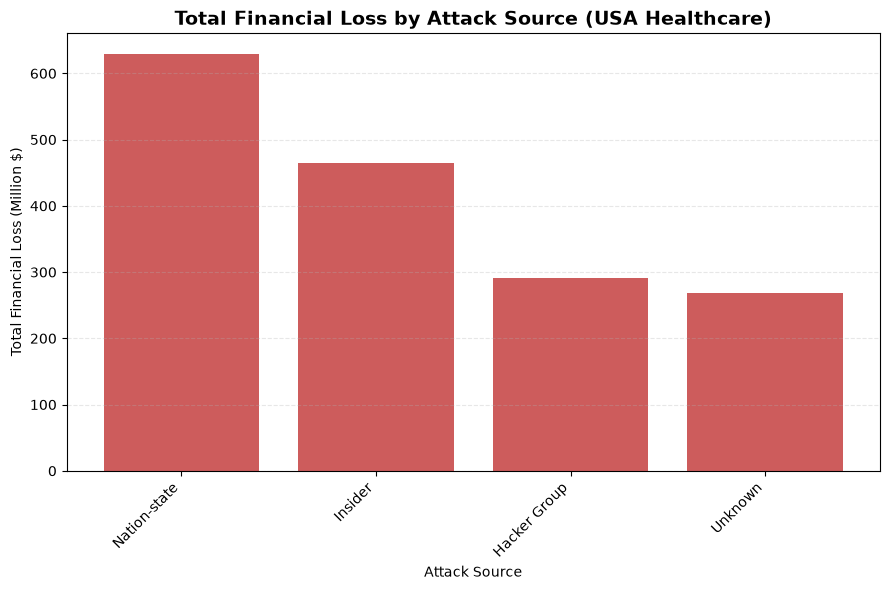

In [88]:

loss_by_source = (
    usa_healthcare
    .groupby("Attack Source")["Financial Loss (in Million $)"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 6))

plt.bar(
    loss_by_source.index,
    loss_by_source.values,
    color="indianred"
)

plt.title("Total Financial Loss by Attack Source (USA Healthcare)", fontsize=14, fontweight="bold")
plt.xlabel("Attack Source")
plt.ylabel("Total Financial Loss (Million $)")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

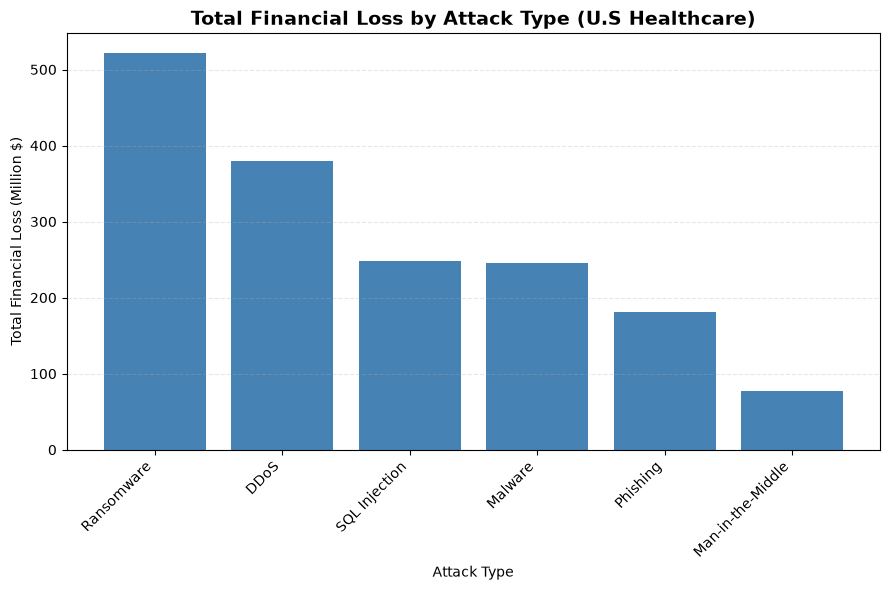

In [89]:

loss_by_attack = (
    usa_healthcare
    .groupby("Attack Type")["Financial Loss (in Million $)"]
    .sum()
    .sort_values(ascending=False)
)


plt.figure(figsize=(9, 6))

plt.bar(loss_by_attack.index, loss_by_attack.values, color="steelblue")

plt.title("Total Financial Loss by Attack Type (U.S Healthcare)",
          fontsize=14, fontweight="bold")
plt.xlabel("Attack Type")
plt.ylabel("Total Financial Loss (Million $)")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

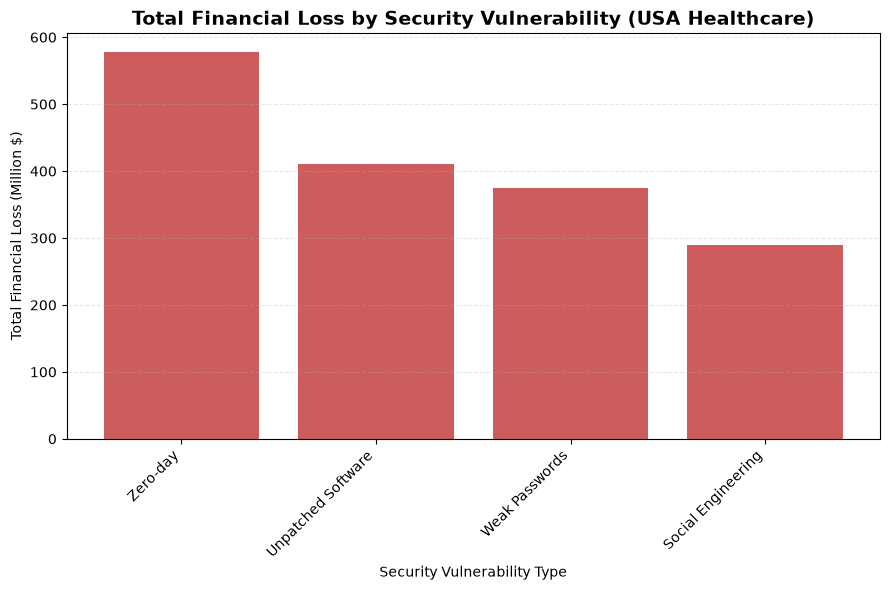

In [90]:

loss_by_vulnerability = (
    usa_healthcare
    .groupby("Security Vulnerability Type")["Financial Loss (in Million $)"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 6))

plt.bar(loss_by_vulnerability.index, loss_by_vulnerability.values, color="indianred")

plt.title("Total Financial Loss by Security Vulnerability (USA Healthcare)",
          fontsize=14, fontweight="bold")
plt.xlabel("Security Vulnerability Type")
plt.ylabel("Total Financial Loss (Million $)")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

In [91]:

defense_counts = (
    usa_healthcare["Defense Mechanism Used"]
    .value_counts()
    .reset_index()
)

defense_counts.columns = ["Defense Mechanism", "Number of Incidents"]

fig = px.bar(
    defense_counts,
    x="Defense Mechanism",
    y="Number of Incidents",
    title="Defense Mechanisms Used in U.S. Healthcare Cyberattacks",
    labels={
        "Defense Mechanism": "Defense Mechanism Used",
        "Number of Incidents": "Number of Incidents"
    },
    text="Number of Incidents"
)

fig.update_layout(
    title_x=0.5,
    template="plotly_white"
)

fig.show()

In [92]:

hospital_financials = pd.read_csv(
    r"C:\Users\joshs\Downloads\CostReport_2024_Final.csv",
    low_memory=False
)

print(hospital_financials.shape)
hospital_financials.head()

(6109, 117)


,rpt_rec_num,Provider CCN,Hospital Name,Street Address,City,State Code,Zip Code,County,Medicare CBSA Number,Rural Versus Urban,...,Net Income from Service to Patients,Total Other Income,Total Income,Total Other Expenses,Net Income,Cost To Charge Ratio,Net Revenue from Medicaid,Medicaid Charges,Net Revenue from Stand-Alone CHIP,Stand-Alone CHIP Charges
0,773939,70040,HEBREW HOME & HOSPITAL,ONE ABRAHAMS BLVD,WEST HARTFORD,CT,06117,HARTFORD,25540.0,U,...,156276.0,39616.0,195892.0,NaN,195892.0,0.831652,NaN,NaN,NaN,NaN
1,775463,360121,COMMUNITY HOSPITAL OF WILLIAMS CITY,433 WEST HIGH,BRYAN,OH,43506-,WILLIAMS,99936.0,R,...,1290034.0,63238711.0,64528745.0,NaN,64528745.0,0.445688,1524035.0,6323756.0,NaN,NaN
2,775808,50855,KFH - SAN MARCOS,360 RUSH DR,SAN MARCOS,CA,92078,SAN DIEGO,41740.0,U,...,37083182.0,268839.0,37352021.0,NaN,37352021.0,0.445902,3594337.0,23693620.0,NaN,4197.0
3,781190,152028,VIBRA HOSPITAL OF NORTHWEST INDIANA,9509 GEORGIA STREET,CROWN POINT,IN,46307-6518,LAKE,23844.0,U,...,-844534.0,8471.0,-836063.0,NaN,-836063.0,NaN,NaN,NaN,NaN,NaN
4,782555,224047,WESTERN MASSACHUSETTS BEHAVIORAL HOS,45 LOWER WESTFIELD ROAD,HOLYOKE,MA,01040,HAMPDEN,44140.0,U,...,-2631473.0,556.0,-2630917.0,NaN,-2630917.0,NaN,NaN,NaN,NaN,NaN


In [93]:
hospital_financials.columns = (
    hospital_financials.columns
    .str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

hospital_financials.head()

,rpt_rec_num,provider_ccn,hospital_name,street_address,city,state_code,zip_code,county,medicare_cbsa_number,rural_versus_urban,...,net_income_from_service_to_patients,total_other_income,total_income,total_other_expenses,net_income,cost_to_charge_ratio,net_revenue_from_medicaid,medicaid_charges,net_revenue_from_stand_alone_chip,stand_alone_chip_charges
0,773939,70040,HEBREW HOME & HOSPITAL,ONE ABRAHAMS BLVD,WEST HARTFORD,CT,06117,HARTFORD,25540.0,U,...,156276.0,39616.0,195892.0,NaN,195892.0,0.831652,NaN,NaN,NaN,NaN
1,775463,360121,COMMUNITY HOSPITAL OF WILLIAMS CITY,433 WEST HIGH,BRYAN,OH,43506-,WILLIAMS,99936.0,R,...,1290034.0,63238711.0,64528745.0,NaN,64528745.0,0.445688,1524035.0,6323756.0,NaN,NaN
2,775808,50855,KFH - SAN MARCOS,360 RUSH DR,SAN MARCOS,CA,92078,SAN DIEGO,41740.0,U,...,37083182.0,268839.0,37352021.0,NaN,37352021.0,0.445902,3594337.0,23693620.0,NaN,4197.0
3,781190,152028,VIBRA HOSPITAL OF NORTHWEST INDIANA,9509 GEORGIA STREET,CROWN POINT,IN,46307-6518,LAKE,23844.0,U,...,-844534.0,8471.0,-836063.0,NaN,-836063.0,NaN,NaN,NaN,NaN,NaN
4,782555,224047,WESTERN MASSACHUSETTS BEHAVIORAL HOS,45 LOWER WESTFIELD ROAD,HOLYOKE,MA,01040,HAMPDEN,44140.0,U,...,-2631473.0,556.0,-2630917.0,NaN,-2630917.0,NaN,NaN,NaN,NaN,NaN


In [94]:
hospital_financials.info()

hospital_financials[
    ["hospital_name", "state_code",
     "fiscal_year_begin_date", "fiscal_year_end_date",
     "total_costs", "net_income"]
].head()

<class 'pandas.DataFrame'>
RangeIndex: 6109 entries, 0 to 6108
Columns: 117 entries, rpt_rec_num to stand_alone_chip_charges
dtypes: float64(103), int64(4), str(10)
memory usage: 5.5 MB


,hospital_name,state_code,fiscal_year_begin_date,fiscal_year_end_date,total_costs,net_income
0,HEBREW HOME & HOSPITAL,CT,10/01/2023,12/19/2023,2278766.0,195892.0
1,COMMUNITY HOSPITAL OF WILLIAMS CITY,OH,10/01/2023,12/31/2023,20503814.0,64528745.0
2,KFH - SAN MARCOS,CA,10/11/2023,12/31/2023,100389294.0,37352021.0
3,VIBRA HOSPITAL OF NORTHWEST INDIANA,IN,11/01/2023,12/31/2023,2151453.0,-836063.0
4,WESTERN MASSACHUSETTS BEHAVIORAL HOS,MA,11/22/2023,12/31/2023,6002975.0,-2630917.0


In [95]:
hospital_financials.duplicated(
    subset=["provider_ccn", "fiscal_year_begin_date",
            "fiscal_year_end_date"]
).sum()

np.int64(0)

In [96]:

hospital_info = pd.read_csv(r"C:\Users\joshs\Downloads\Hospital_General_Information.csv")

hospital_info.head()

,Facility ID,Facility Name,Address,City/Town,State,ZIP Code,County/Parish,Telephone Number,Hospital Type,Hospital Ownership,...,Count of READM Measures Better,Count of READM Measures No Different,Count of READM Measures Worse,READM Group Footnote,Pt Exp Group Measure Count,Count of Facility Pt Exp Measures,Pt Exp Group Footnote,TE Group Measure Count,Count of Facility TE Measures,TE Group Footnote
0,010001,SOUTHEAST HEALTH MEDICAL CENTER,1108 ROSS CLARK CIRCLE,DOTHAN,AL,36301,HOUSTON,(334) 793-8701,Acute Care Hospitals,Government - Hospital District or Authority,...,1,9,1,NaN,15,15,NaN,10,10,NaN
1,010005,MARSHALL MEDICAL CENTERS,2505 U S HIGHWAY 431 NORTH,BOAZ,AL,35957,MARSHALL,(256) 593-8310,Acute Care Hospitals,Government - Hospital District or Authority,...,1,8,0,NaN,15,15,NaN,10,10,NaN
2,010006,NORTH ALABAMA MEDICAL CENTER,1701 VETERANS DRIVE,FLORENCE,AL,35630,LAUDERDALE,(256) 768-8400,Acute Care Hospitals,Proprietary,...,1,8,0,NaN,15,15,NaN,10,9,NaN
3,010007,MIZELL MEMORIAL HOSPITAL,702 N MAIN ST,OPP,AL,36467,COVINGTON,(334) 493-3541,Acute Care Hospitals,Voluntary non-profit - Private,...,0,3,2,NaN,15,5,NaN,10,7,NaN
4,010011,ST. VINCENT'S EAST,50 MEDICAL PARK EAST DRIVE,BIRMINGHAM,AL,35235,JEFFERSON,(205) 838-3122,Acute Care Hospitals,Voluntary non-profit - Private,...,1,5,2,29.0,15,10,29.0,10,7,29.0


In [97]:
states_to_remove = ["VI", "GU", "AS", "MP"]


hospital_info = hospital_info[
    ~hospital_info["State"].isin(states_to_remove)
]


hospitals_per_state = (
    hospital_info.groupby("State")["Facility ID"]
    .nunique()
    .reset_index(name="Number of Hospitals")
    .sort_values(by="Number of Hospitals", ascending=False)
)

print(hospitals_per_state)

   State  Number of Hospitals
44    TX                  467
4     CA                  377
9     FL                  221
14    IL                  193
35    OH                  193
34    NY                  192
38    PA                  186
18    LA                  161
10    GA                  149
22    MI                  149
15    IN                  148
49    WI                  140
16    KS                  139
36    OK                  136
23    MN                  136
43    TN                  121
27    NC                  120
24    MO                  120
12    IA                  118
25    MS                  109
3     AZ                  108
17    KY                  103
48    WA                  100
1     AL                   99
5     CO                   96
46    VA                   96
29    NE                   93
2     AR                   90
19    MA                   84
31    NJ                   78
41    SC                   66
26    MT                   63
37    OR  

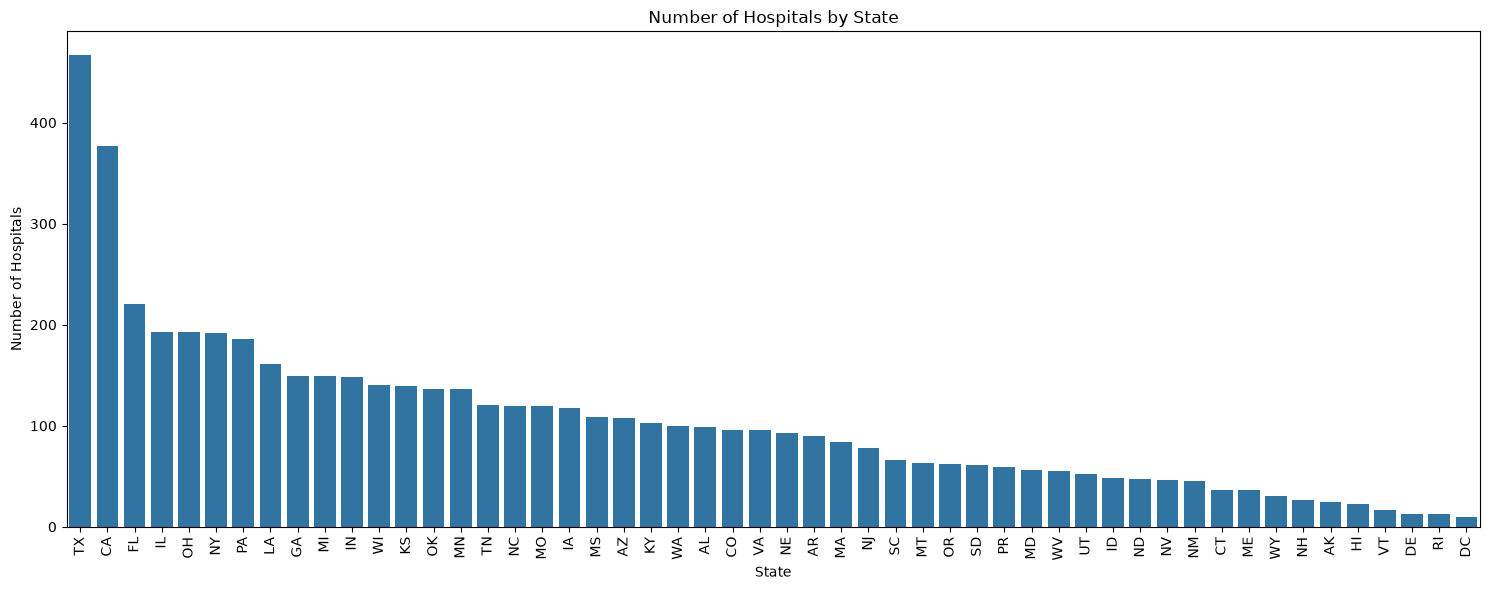

In [98]:
plt.figure(figsize=(15, 6))

sns.barplot(
    data=hospitals_per_state,
    x="State",
    y="Number of Hospitals"
)

plt.title("Number of Hospitals by State")
plt.xlabel("State")
plt.ylabel("Number of Hospitals")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [99]:

breaches_since_2016 = breaches[
    pd.to_numeric(breaches["breach_year"], errors="coerce") >= 2016
].copy()


state_breaches_2016 = (
    breaches_since_2016
    .groupby("state")
    .size()
    .reset_index(name="breach_count")
)

state_breaches_2016["state"] = (
    state_breaches_2016["state"].str.strip().str.upper()
)

hospitals_per_state["State"] = (
    hospitals_per_state["State"].str.strip().str.upper()
)


state_comparison = state_breaches_2016.merge(
    hospitals_per_state,
    left_on="state",
    right_on="State",
    how="inner"
)


state_comparison["Breaches per Hospital"] = (
    state_comparison["breach_count"]
    / state_comparison["Number of Hospitals"]
)


fig = px.choropleth(
    state_comparison,
    locations="state",
    locationmode="USA-states",
    color="Breaches per Hospital",
    scope="usa",
    color_continuous_scale="Reds",
    hover_name="state",
    hover_data={
        "breach_count": True,
        "Number of Hospitals": True,
        "Breaches per Hospital": ":.3f",
        "state": False
    },
    labels={
        "breach_count": "Data Breaches Since 2016",
        "Number of Hospitals": "Number of Hospitals",
        "Breaches per Hospital": "Breaches per Hospital"
    },
    title="Healthcare Data Breaches per Hospital by State (2016–Present)"
)

fig.update_layout(
    title_x=0.5,
    geo=dict(showlakes=True, lakecolor="white")
)

fig.show()

In [100]:

breaches_since_2016 = breaches[
    pd.to_numeric(breaches["breach_year"], errors="coerce") >= 2016
].copy()


state_breaches_2016 = (
    breaches_since_2016
    .groupby("state")
    .size()
    .reset_index(name="breach_count")
)


state_breaches_2016["state"] = (
    state_breaches_2016["state"].str.strip().str.upper()
)

hospitals_per_state["State"] = (
    hospitals_per_state["State"].str.strip().str.upper()
)


state_comparison = state_breaches_2016.merge(
    hospitals_per_state,
    left_on="state",
    right_on="State",
    how="inner"
)


state_comparison["Breaches per Hospital"] = (
    state_comparison["breach_count"]
    / state_comparison["Number of Hospitals"]
)


fig = px.choropleth(
    state_comparison,
    locations="state",
    locationmode="USA-states",
    color="Breaches per Hospital",
    scope="usa",
    color_continuous_scale="Reds",
    hover_name="state",
    hover_data={
        "breach_count": True,
        "Number of Hospitals": True,
        "Breaches per Hospital": ":.3f",
        "state": False
    },
    labels={
        "breach_count": "Data Breaches Since 2016",
        "Number of Hospitals": "Number of Hospitals",
        "Breaches per Hospital": "Breaches per Hospital"
    },
    title="Healthcare Data Breaches per Hospital by State (2016–Present)",
    width=850,
    height=750
)


fig.update_layout(
    title_x=0.5,
    margin=dict(l=20, r=20, t=75, b=20),
    coloraxis_colorbar=dict(
        title="Breaches<br>per Hospital"
    ),
    geo=dict(
        showlakes=True,
        lakecolor="white"
    )
)

fig.show()

In [101]:

healthcare_providers = breaches[
    breaches["entity_type"].str.strip().str.lower()
    == "healthcare provider"
].copy()


print("Total healthcare provider breach records:", len(healthcare_providers))

display(healthcare_providers.head())

Total healthcare provider breach records: 5786


,entity name,state,entity_type,individuals_affected,breach_submission_date,breach_type,location_of_breach,Yes/No,web_description,breach_year,breach_month,record_status,breach_size_category,log_individuals_affected,location_grouped_2pct
2,"Desert Pulmonary & Sleep Consultants, P.L.C.",AZ,Healthcare Provider,3000.0,2026-08-25,Unauthorized Access/Disclosure,"Electronic Medical Record, Network Server",No,"The covered entity (CE), Desert Pulmonary & Sl...",2026,8,Archived,"1,001-10,000",8.006701,Other
5,Silver Summit Medical Corporation,CA,Healthcare Provider,11349.0,2026-08-19,Hacking/IT Incident,"Network Server, Other",Yes,"The covered entity (CE), Silver Summit Medical...",2026,8,Archived,"10,001-100,000",9.336973,Other
6,The Healthy Woman,GA,Healthcare Provider,2750.0,2026-08-09,Unauthorized Access/Disclosure,Email,No,"The covered entity (CE), The Healthy Woman, re...",2026,8,Archived,"1,001-10,000",7.919720,Email
9,University of California Los Angeles Health,CA,Healthcare Provider,6050.0,2026-08-04,Unauthorized Access/Disclosure,Electronic Medical Record,No,NaN,2026,8,Archived,"1,001-10,000",8.707979,Electronic Medical Record
12,Brookhaven ENT Allergy and Facial Surgery,MS,Healthcare Provider,30403.0,2026-07-24,Hacking/IT Incident,"Electronic Medical Record, Network Server",Yes,"The covered entity (CE), Brookhaven ENT Allerg...",2026,7,Archived,"10,001-100,000",10.322329,Other


In [102]:

import statsmodels.formula.api as smf

model_data = breaches.copy()

model_data["individuals_affected"] = pd.to_numeric(
    model_data["individuals_affected"], errors="coerce"
)

model_data["breach_year"] = pd.to_numeric(
    model_data["breach_year"], errors="coerce"
)

model_data = model_data.dropna(
    subset=["individuals_affected", "breach_year"]
).copy()

model_data = model_data[
    model_data["individuals_affected"] >= 0
].copy()

model_data["log_individuals_affected"] = np.log1p(
    model_data["individuals_affected"]
)

categorical_vars = [
    "breach_type",
    "entity_type",
    "location_of_breach",
    "state"
]

MIN_COUNT = 100

for col in categorical_vars:
    counts = model_data[col].value_counts()
    common_categories = counts[counts >= MIN_COUNT].index

    model_data = model_data[
        model_data[col].isin(common_categories)
    ].copy()

for col in categorical_vars:
    model_data[col] = (
        model_data[col]
        .fillna("Unknown")
        .astype(str)
        .str.strip()
        .replace("", "Unknown")
    )

print("Observations available:", len(model_data))
print("\nMissing values:")
print(
    model_data[
        ["log_individuals_affected", "breach_year"]
        + categorical_vars
    ].isna().sum()
)


print("\nlocation_of_breach:")
print(model_data["location_of_breach"].value_counts())


Observations available: 6044

Missing values:
log_individuals_affected    0
breach_year                 0
breach_type                 0
entity_type                 0
location_of_breach          0
state                       0
dtype: int64

location_of_breach:
location_of_breach
Network Server                      2796
Email                               1444
Paper/Films                          691
Laptop                               311
Electronic Medical Record            252
Other                                239
Other Portable Electronic Device     157
Desktop Computer                     154
Name: count, dtype: int64


In [103]:
formula = """
log_individuals_affected
~ breach_year + C(breach_type)
+ C(location_of_breach)
+ C(state)
+ C(entity_type)
"""

model = smf.ols(
    formula=formula,
    data=model_data
).fit(cov_type="HC3")

print(model.summary())

                               OLS Regression Results                               
Dep. Variable:     log_individuals_affected   R-squared:                       0.168
Model:                                  OLS   Adj. R-squared:                  0.163
Method:                       Least Squares   F-statistic:                     36.03
Date:                      Sun, 22 Nov 2026   Prob (F-statistic):          7.45e-235
Time:                              21:55:19   Log-Likelihood:                -12295.
No. Observations:                      6044   AIC:                         2.467e+04
Df Residuals:                          6005   BIC:                         2.493e+04
Df Model:                                38                                         
Covariance Type:                        HC3                                         
                                                                coef    std err          z      P>|z|      [0.025      0.975]
------------------------

In [104]:
model_data["year_centered"] = (
    model_data["breach_year"] - model_data["breach_year"].mean()
)


In [105]:
formula2 = """
log_individuals_affected
 ~ year_centered + I(year_centered**2)
+ C(breach_type)
+ C(location_of_breach)
+ C(state)
+ C(entity_type)
"""

model2 = smf.ols(
    formula=formula2,
    data=model_data
).fit(cov_type="HC3")

print(model2.summary())

                               OLS Regression Results                               
Dep. Variable:     log_individuals_affected   R-squared:                       0.171
Model:                                  OLS   Adj. R-squared:                  0.166
Method:                       Least Squares   F-statistic:                     35.76
Date:                      Sun, 22 Nov 2026   Prob (F-statistic):          1.49e-238
Time:                              21:55:19   Log-Likelihood:                -12285.
No. Observations:                      6044   AIC:                         2.465e+04
Df Residuals:                          6004   BIC:                         2.492e+04
Df Model:                                39                                         
Covariance Type:                        HC3                                         
                                                                coef    std err          z      P>|z|      [0.025      0.975]
------------------------

In [106]:
formula3 = """
log_individuals_affected
~ breach_year
+ C(breach_type) * C(entity_type)
+ C(location_of_breach)
+ C(state)
"""

model3 = smf.ols(
    formula=formula3,
    data=model_data
).fit(cov_type="HC3")

print(model3.summary())

                               OLS Regression Results                               
Dep. Variable:     log_individuals_affected   R-squared:                       0.175
Model:                                  OLS   Adj. R-squared:                  0.168
Method:                       Least Squares   F-statistic:                     32.81
Date:                      Sun, 22 Nov 2026   Prob (F-statistic):          7.30e-253
Time:                              21:55:19   Log-Likelihood:                -12271.
No. Observations:                      6044   AIC:                         2.464e+04
Df Residuals:                          5997   BIC:                         2.495e+04
Df Model:                                46                                         
Covariance Type:                        HC3                                         
                                                                                             coef    std err          z      P>|z|      [0.025      0.

In [107]:

classification_data = model_data.dropna(
    subset=["individuals_affected"]
).copy()


classification_data["large_breach"] = (
    classification_data["individuals_affected"] > 20000
).astype(int)


print(classification_data["large_breach"].value_counts())

print(
    classification_data["large_breach"]
    .value_counts(normalize=True) * 100
)

large_breach
0    4497
1    1547
Name: count, dtype: int64
large_breach
0    74.404368
1    25.595632
Name: proportion, dtype: float64


In [108]:
from sklearn.model_selection import train_test_split


X = classification_data[
    [
        "breach_year",
        "breach_type",
        "location_of_breach",
        "state",
        "entity_type"
    ]
]


y = classification_data["large_breach"]


X = pd.get_dummies(X, drop_first=True, dtype=int)


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (4533, 38)
Testing set: (1511, 38)


In [109]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    accuracy_score
)


log_model = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)

log_model.fit(X_train, y_train)


y_pred = log_model.predict(X_test)
y_prob = log_model.predict_proba(X_test)[:, 1]


print("Accuracy:", accuracy_score(y_test, y_pred))
print("ROC AUC:", roc_auc_score(y_test, y_prob))
print("PR AUC", average_precision_score(y_test, y_prob))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Accuracy: 0.6730641958967571
ROC AUC: 0.7230636247436711
PR AUC 0.432152767554075

Confusion Matrix:
[[736 388]
 [106 281]]

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.65      0.75      1124
           1       0.42      0.73      0.53       387

    accuracy                           0.67      1511
   macro avg       0.65      0.69      0.64      1511
weighted avg       0.76      0.67      0.69      1511



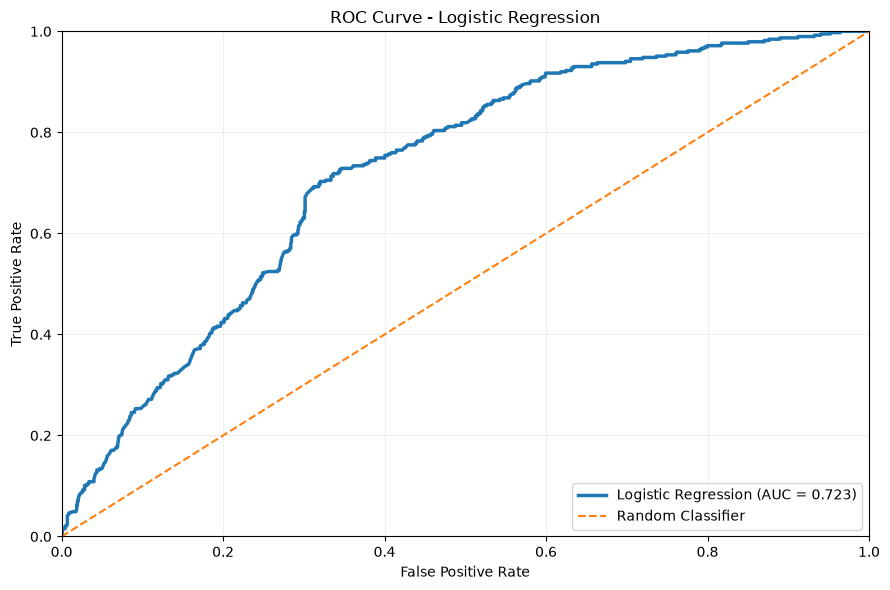

In [110]:

from sklearn.metrics import roc_curve, roc_auc_score


fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)


plt.figure(figsize=(9, 6))

plt.plot(
    fpr,
    tpr,
    linewidth=2.5,
    label=f"Logistic Regression (AUC = {auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [111]:
log_coefficients = pd.DataFrame({
    "Variable": X_train.columns,
    "Coefficient": log_model.coef_[0]
})

log_coefficients["Odds Ratio"] = np.exp(log_coefficients["Coefficient"])

log_coefficients = log_coefficients.sort_values(
    by="Coefficient",
    ascending=False
)

display(log_coefficients)

,Variable,Coefficient,Odds Ratio
8,location_of_breach_Network Server,1.052360,2.864403
31,state_TN,0.355622,1.427068
16,state_GA,0.336284,1.399737
32,state_TX,0.278530,1.321186
15,state_FL,0.225588,1.253059
27,state_NY,0.215630,1.240643
5,location_of_breach_Electronic Medical Record,0.193892,1.213965
21,state_MD,0.186378,1.204877
24,state_MO,0.171352,1.186909
13,state_CO,0.159742,1.173208


In [112]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score
)

numeric_features = ["breach_year"]

categorical_features = [
    "breach_type",
    "location_of_breach",
    "state",
    "entity_type"
]

X = classification_data[
    numeric_features + categorical_features
]

y = classification_data["large_breach"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            SimpleImputer(strategy="median"),
            numeric_features
        ),
        (
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore"))
            ]),
            categorical_features
        )
    ]
)


rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=10,
        min_samples_split=10,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])


rf_model.fit(X_train, y_train)


rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]


print("Balanced Accuracy:",
      balanced_accuracy_score(y_test, rf_pred))

print("ROC AUC:",
      roc_auc_score(y_test, rf_prob))

print("PR AUC:",
      average_precision_score(y_test, rf_prob))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

print("\nClassification Report:")
print(classification_report(y_test, rf_pred))

Balanced Accuracy: 0.7012515287778054
ROC AUC: 0.7516414245910232
PR AUC: 0.48172010229188683

Confusion Matrix:
[[708 416]
 [ 88 299]]

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.63      0.74      1124
           1       0.42      0.77      0.54       387

    accuracy                           0.67      1511
   macro avg       0.65      0.70      0.64      1511
weighted avg       0.77      0.67      0.69      1511



In [113]:

feature_names = rf_model.named_steps["preprocessor"].get_feature_names_out()


importance_scores = rf_model.named_steps["classifier"].feature_importances_


rf_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_scores
})


rf_importance = rf_importance.sort_values(
    by="Importance",
    ascending=False
)

In [114]:

feature_names = rf_model.named_steps["preprocessor"].get_feature_names_out()
importance_scores = rf_model.named_steps["classifier"].feature_importances_


rf_importance = pd.DataFrame({
    "Feature": feature_names,
    "Gini Importance": importance_scores
})


rf_importance["Variable"] = rf_importance["Feature"].str.replace(
    r"^(num|cat)__", "", regex=True
).str.split("_").str[0]


grouped_gini = (
    rf_importance.groupby("Variable")["Gini Importance"]
    .sum()
    .reset_index()
    .sort_values("Gini Importance", ascending=False)
)

display(grouped_gini)

,Variable,Gini Importance
0,breach,0.497406
2,location,0.346596
3,state,0.107253
1,entity,0.048745


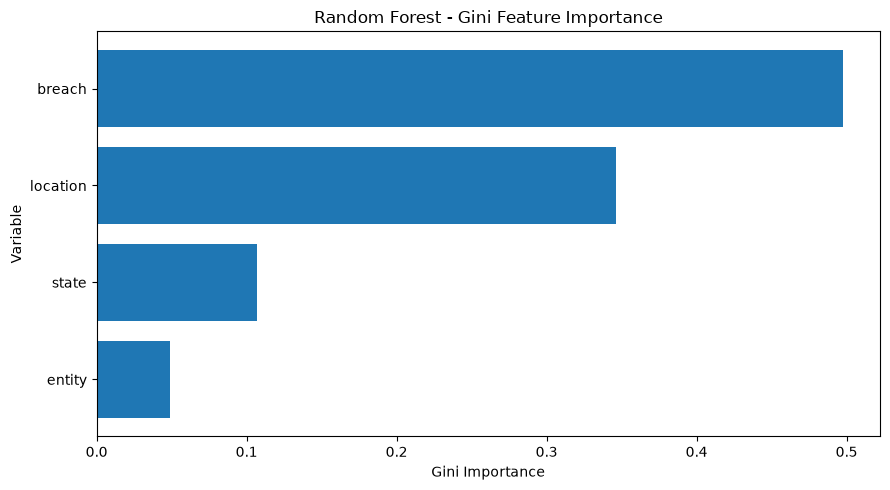

In [115]:
plt.figure(figsize=(9, 5))

plt.barh(
    grouped_gini["Variable"],
    grouped_gini["Gini Importance"]
)

plt.xlabel("Gini Importance")
plt.ylabel("Variable")
plt.title("Random Forest - Gini Feature Importance")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [116]:

numeric_features = ["breach_year"]

categorical_features = [
    "breach_type",
    "location_of_breach",
    "state",
    "entity_type"
]

X = classification_data[numeric_features + categorical_features]
y = classification_data["large_breach"]


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [117]:
from sklearn.inspection import permutation_importance


perm_results = permutation_importance(
    rf_model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring="roc_auc",
    n_jobs=-1
)


grouped_permutation = pd.DataFrame({
    "Variable": X_test.columns,
    "Permutation Importance": perm_results.importances_mean
})

grouped_permutation = grouped_permutation.sort_values(
    "Permutation Importance",
    ascending=False
)

display(grouped_permutation)

,Variable,Permutation Importance
2,location_of_breach,0.097541
1,breach_type,0.069881
0,breach_year,0.027675
4,entity_type,0.017150
3,state,0.004451


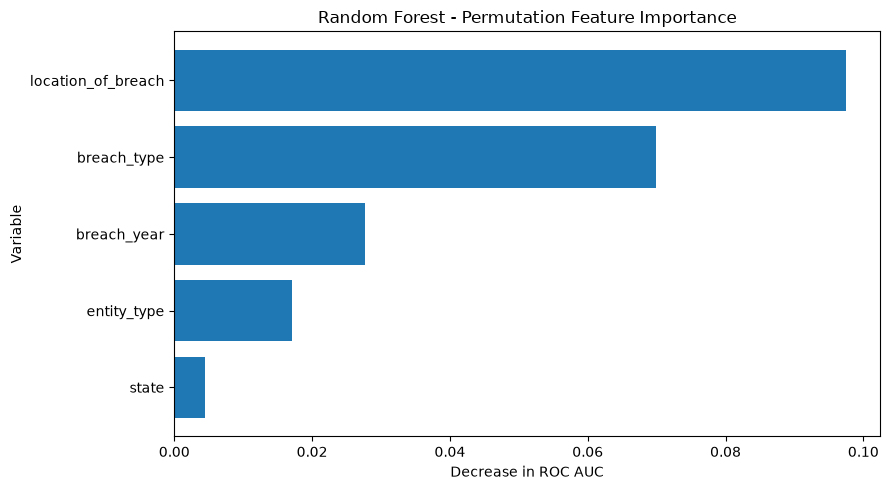

In [118]:
plt.figure(figsize=(9, 5))

plt.barh(
    grouped_permutation["Variable"],
    grouped_permutation["Permutation Importance"]
)

plt.xlabel("Decrease in ROC AUC")
plt.ylabel("Variable")
plt.title("Random Forest - Permutation Feature Importance")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [119]:
rf_prob = rf_model.predict_proba(X_test)[:, 1]

# Calculate ROC curve
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, thresholds = roc_curve(y_test, rf_prob)

auc = roc_auc_score(y_test, rf_prob)

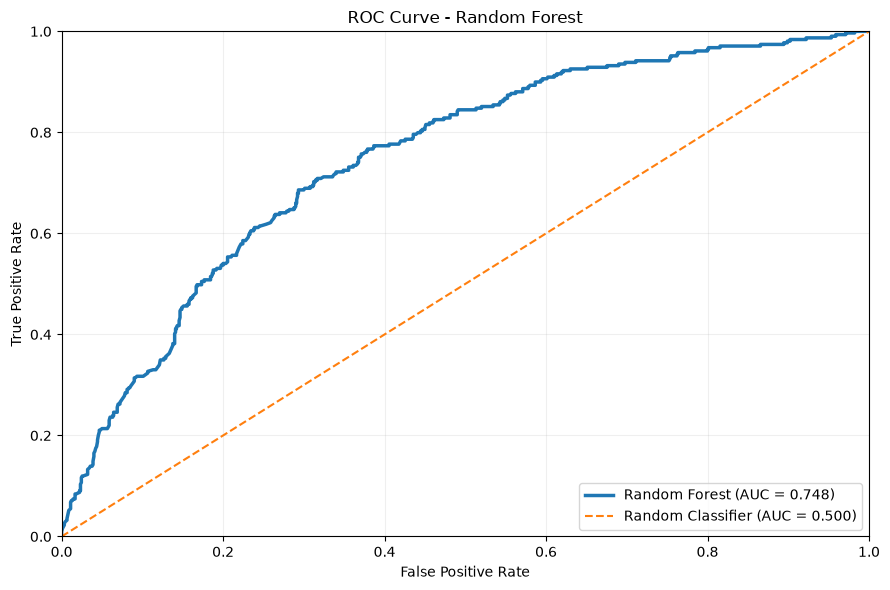

In [120]:
plt.figure(figsize=(9, 6))

plt.plot(
    fpr,
    tpr,
    linewidth=2.5,
    label=f"Random Forest (AUC = {auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random Classifier (AUC = 0.500)"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Random Forest")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [121]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [122]:
hospital_financials["provider_ccn"] = (
    hospital_financials["provider_ccn"]
    .astype("string")
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(6)
)

hospital_info["Facility ID"] = (
    hospital_info["Facility ID"]
    .astype("string")
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(6)
)

merged_hospitals = hospital_financials.merge(
    hospital_info,
    left_on="provider_ccn",
    right_on="Facility ID",
    how="left",
    indicator=True
)

C:\Users\joshs\AppData\Local\Temp\ipykernel_29348\707193038.py:15: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  merged_hospitals = hospital_financials.merge(
C:\Users\joshs\AppData\Local\Temp\ipykernel_29348\707193038.py:15: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  merged_hospitals = hospital_financials.merge(


In [123]:
print(merged_hospitals["_merge"].value_counts())

_merge
both          5248
left_only      861
right_only       0
Name: count, dtype: int64


In [124]:
matched = (merged_hospitals["_merge"] == "both").sum()
total = len(merged_hospitals)

print(f"Matched: {matched} out of {total}")
print(f"Match rate: {matched / total:.2%}")

Matched: 5248 out of 6109
Match rate: 85.91%


In [125]:

name_comparison = merged_hospitals[
    merged_hospitals["_merge"] == "both"
][
    [
        "provider_ccn",
        "hospital_name",
        "Facility Name",
        "state_code",
        "State"
    ]
].copy()

display(name_comparison.head(30))

,provider_ccn,hospital_name,Facility Name,state_code,State
1,360121,COMMUNITY HOSPITAL OF WILLIAMS CITY,COMMUNITY HOSPITALS AND WELLNESS CENTERS,OH,OH
2,050855,KFH - SAN MARCOS,KAISER FOUNDATION HOSPITAL - SAN MARCOS,CA,CA
4,224047,WESTERN MASSACHUSETTS BEHAVIORAL HOS,VALLEY SPRINGS BEHAVIORAL HEALTH HOSPITAL,MA,MA
5,050481,WEST HILLS HOSPITAL,UCLA WEST VALLEY MEDICAL CENTER,CA,CA
7,180009,KINGS DAUGHTERS MEDICAL CENTER,KING'S DAUGHTERS' MEDICAL CENTER,KY,KY
8,360361,KINGS DAUGHTERS MED CENTER OHIO,KINGS DAUGHTERS MEDICAL CENTER OHIO,OH,OH
9,194120,STONEBRIDGE BEHAVIORAL HOSPITAL,STONEBRIDGE BEHAVIORAL HOSPITAL,LA,LA
14,050570,FOUNTAIN VALLEY REG MEDICAL CENTER,UCI HEALTH - FOUNTAIN VALLEY,CA,CA
19,170049,OLATHE MEDICAL CENTER,UNIVERSITY OF KANSAS HEALTH SYSTEM OLATHE HOSP...,KS,KS
20,210002,UNIVERSITY OF MARYLAND MED SYS,UNIVERSITY OF MARYLAND MEDICAL CENTER,MD,MD


In [126]:
import pandas as pd
import numpy as np
import os
import glob
import re

folder_path = r"C:\Users\joshs\Downloads\HospitalFinancials"

csv_files = glob.glob(os.path.join(folder_path, "*.csv"))

print("Number of CSV files found:", len(csv_files))

historical_data = []

for file in csv_files:

    df = pd.read_csv(file)

    match = re.search(r'20\d{2}|19\d{2}', os.path.basename(file))

    if match:
        year = int(match.group())
    
        df["fiscal_year"] = year

        historical_data.append(df)

    else:
        print("Could not identify year:", os.path.basename(file))

historical_financials = pd.concat(
    historical_data,
    ignore_index=True
)

print("Combined financials shape:", historical_financials.shape)

historical_financials.head()

Number of CSV files found: 14


C:\Users\joshs\AppData\Local\Temp\ipykernel_29348\2618080878.py:24: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["fiscal_year"] = year


Combined financials shape: (86212, 118)


,rpt_rec_num,Provider CCN,Hospital Name,Street Address,City,State Code,Zip Code,County,Medicare CBSA Number,Rural Versus Urban,...,Total Other Income,Total Income,Total Other Expenses,Net Income,Cost To Charge Ratio,Net Revenue from Medicaid,Medicaid Charges,Net Revenue from Stand-Alone CHIP,Stand-Alone CHIP Charges,fiscal_year
0,1022,271326,BEARTOOTH BILLINGS CLINIC,2525 NORTH BROADWAY,RED LODGE,MT,59806,CARBON,99927.0,R,...,725351.0,-837408.0,NaN,-837408.0,1.061421,186460.0,262576.0,NaN,NaN,2011
1,1501,13025,HEALTHSOUTH LAKESHORE HOSPITAL,3800 RIDGEWAY DRIVE,BIRMINGHAM,AL,35209,JEFFERSON,13820.0,U,...,421791.0,11784376.0,21729.0,11762647.0,0.452421,NaN,NaN,NaN,NaN,2011
2,1504,103037,HEALTHSOUTH REHABILITATION HOSPITAL,901 NORTH CLEARWATER-LARGO ROAD,LARGO,FL,33770,PINELLAS,45300.0,U,...,56946.0,4565066.0,NaN,4565066.0,0.663245,NaN,NaN,NaN,NaN,2011
3,1506,103042,HEALTHSOUTH REHAB OF SPRING HILL,12440 CORTEZ BOULEVARD,BROOKSVILLE,FL,34613,HERNANDO,45300.0,U,...,60139.0,4410533.0,NaN,4410533.0,0.521291,NaN,NaN,NaN,NaN,2011
4,1507,141990,HILL TOP CENTER,502 N. WAUKEGAN ROAD,LAKE BLUFF,IL,60044,LAKE,29404.0,U,...,245940.0,-124284.0,NaN,-124284.0,NaN,NaN,NaN,NaN,NaN,2011


In [127]:
historical_financials.columns = (
    historical_financials.columns
    .str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

historical_financials.head()

,rpt_rec_num,provider_ccn,hospital_name,street_address,city,state_code,zip_code,county,medicare_cbsa_number,rural_versus_urban,...,total_other_income,total_income,total_other_expenses,net_income,cost_to_charge_ratio,net_revenue_from_medicaid,medicaid_charges,net_revenue_from_stand_alone_chip,stand_alone_chip_charges,fiscal_year
0,1022,271326,BEARTOOTH BILLINGS CLINIC,2525 NORTH BROADWAY,RED LODGE,MT,59806,CARBON,99927.0,R,...,725351.0,-837408.0,NaN,-837408.0,1.061421,186460.0,262576.0,NaN,NaN,2011
1,1501,13025,HEALTHSOUTH LAKESHORE HOSPITAL,3800 RIDGEWAY DRIVE,BIRMINGHAM,AL,35209,JEFFERSON,13820.0,U,...,421791.0,11784376.0,21729.0,11762647.0,0.452421,NaN,NaN,NaN,NaN,2011
2,1504,103037,HEALTHSOUTH REHABILITATION HOSPITAL,901 NORTH CLEARWATER-LARGO ROAD,LARGO,FL,33770,PINELLAS,45300.0,U,...,56946.0,4565066.0,NaN,4565066.0,0.663245,NaN,NaN,NaN,NaN,2011
3,1506,103042,HEALTHSOUTH REHAB OF SPRING HILL,12440 CORTEZ BOULEVARD,BROOKSVILLE,FL,34613,HERNANDO,45300.0,U,...,60139.0,4410533.0,NaN,4410533.0,0.521291,NaN,NaN,NaN,NaN,2011
4,1507,141990,HILL TOP CENTER,502 N. WAUKEGAN ROAD,LAKE BLUFF,IL,60044,LAKE,29404.0,U,...,245940.0,-124284.0,NaN,-124284.0,NaN,NaN,NaN,NaN,NaN,2011


In [128]:
historical_financials["provider_ccn"] = (
    historical_financials["provider_ccn"]
    .astype("string")
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(6)
)

hospital_info["Facility ID"] = (
    hospital_info["Facility ID"]
    .astype("string")
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(6)
)


In [129]:
merged_hospitals = historical_financials.merge(
    hospital_info,
    left_on="provider_ccn",
    right_on="Facility ID",
    how="inner"
)

In [130]:
print("Original financial records:", len(historical_financials))
print("Records after inner join:", len(merged_hospitals))

print("\nRecords by fiscal year:")
print(merged_hospitals["fiscal_year"].value_counts().sort_index())

Original financial records: 86212
Records after inner join: 69221

Records by fiscal year:
fiscal_year
2011    4620
2012    4725
2013    4767
2014    4823
2015    4864
2016    4898
2017    4911
2018    4984
2019    5016
2020    5036
2021    5085
2022    5086
2023    5158
2024    5248
Name: count, dtype: int64


In [131]:

name_comparison = merged_hospitals[
    [
        "provider_ccn",
        "hospital_name",
        "Facility Name",
        "state_code",
        "State",
        "fiscal_year"
    ]
].copy()

display(name_comparison.tail(10))

,provider_ccn,hospital_name,Facility Name,state_code,State,fiscal_year
69211,191318,TRINITY MEDICAL,RIVERLAND MEDICAL CENTER,LA,LA,2024
69212,241379,PRAIRIE RIDGE HOSPITAL,PRAIRIE RIDGE HOSPITAL AND HEALTH SERVICES,MN,MN,2024
69213,310039,RARITAN BAY MEDICAL CENTER,RARITAN BAY MEDICAL CENTER,NJ,NJ,2024
69214,314027,CORNERSTONE BEHAVIORAL HEALTH HOSPIT,MOUNTAINVIEW BEHAVIORAL HOSPITAL,NJ,NJ,2024
69215,360230,HILLCREST HOSPITAL,HILLCREST HOSPITAL,OH,OH,2024
69216,390004,HOLY SPIRIT HOSPITAL,PENN STATE HEALTH HOLY SPIRIT MEDICAL CENTER,PA,PA,2024
69217,400021,HOSPITAL DE LA CONCEPCION,HOSPITAL DE LA CONCEPCION,PR,PR,2024
69218,440156,PARKRIDGE MEDICAL CENTER,PARKRIDGE MEDICAL CENTER,TN,TN,2024
69219,470003,UNIVERSITY OF VERMONT MEDICAL CENTER,UNIV. OF VERMONT - FLETCHER ALLEN HEALTH CARE,VT,VT,2024
69220,521318,LADD MEMORIAL HOSPTIAL,LADD MEMORIAL HOSPITAL,WI,WI,2024


In [132]:
hospitals_by_state = (
    historical_financials
    .groupby("state_code")["provider_ccn"]
    .nunique()
    .reset_index()
)

hospitals_by_state.columns = ["state", "hospital_count"]

display(hospitals_by_state.sort_values(
    "hospital_count", ascending=False
))

,state,hospital_count
47,TX,773
5,CA,465
10,FL,303
38,OH,275
41,PA,264
20,LA,263
37,NY,236
16,IL,226
17,IN,198
11,GA,196


In [133]:

breaches_by_state = (
    breaches
    .groupby("state")
    .agg(
        total_breaches=("state", "size"),
        total_individuals_affected=("individuals_affected", "sum"),
        average_breach_size=("individuals_affected", "mean"),
        median_breach_size=("individuals_affected", "median")
    )
    .reset_index()
)

display(breaches_by_state.sort_values(
    "total_breaches", ascending=False
))

,state,total_breaches,total_individuals_affected,average_breach_size,median_breach_size
4,CA,786,79958213.0,1.017280e+05,3569.5
44,TX,653,49848611.0,7.633784e+04,4083.0
34,NY,516,42564803.0,8.248993e+04,5442.0
9,FL,471,54072220.0,1.148030e+05,4912.0
14,IL,364,22594404.0,6.207254e+04,3499.5
38,PA,345,21205627.0,6.146559e+04,3904.0
35,OH,278,18927883.0,6.808591e+04,2757.5
19,MA,245,28765571.0,1.174105e+05,3900.0
22,MI,240,16130988.0,6.721245e+04,3738.0
10,GA,229,38859277.0,1.696912e+05,5000.0


In [134]:
state_comparison = hospitals_by_state.merge(
    breaches_by_state,
    on="state",
    how="outer"
)

count_columns = [
    "hospital_count",
    "total_breaches",
    "total_individuals_affected"
]

state_comparison[count_columns] = (
    state_comparison[count_columns].fillna(0)
)

state_comparison["breaches_per_100_hospitals"] = (
    state_comparison["total_breaches"]
    / state_comparison["hospital_count"]
    * 100
)

state_comparison = state_comparison.sort_values(
    "breaches_per_100_hospitals",
    ascending=False
)

display(state_comparison)

,state,hospital_count,total_breaches,total_individuals_affected,average_breach_size,median_breach_size,breaches_per_100_hospitals
7,CT,45,146.0,11358523.0,7.779810e+04,5001.0,324.444444
8,DC,13,34.0,741808.0,2.181788e+04,2908.0,261.538462
43,RI,16,41.0,544697.0,1.328529e+04,4000.0,256.250000
22,MD,69,171.0,19567286.0,1.144286e+05,4792.0,247.826087
37,NY,236,516.0,42564803.0,8.248993e+04,5442.0,218.644068
21,MA,117,245.0,28765571.0,1.174105e+05,3900.0,209.401709
9,DE,16,32.0,5341160.0,1.669112e+05,12973.5,200.000000
40,OR,64,120.0,5405904.0,4.504920e+04,2350.0,187.500000
34,NJ,102,177.0,79985058.0,4.518930e+05,5530.0,173.529412
5,CA,465,786.0,79958213.0,1.017280e+05,3569.5,169.032258


In [135]:
print(historical_financials.columns.tolist())

['rpt_rec_num', 'provider_ccn', 'hospital_name', 'street_address', 'city', 'state_code', 'zip_code', 'county', 'medicare_cbsa_number', 'rural_versus_urban', 'ccn_facility_type', 'provider_type', 'type_of_control', 'fiscal_year_begin_date', 'fiscal_year_end_date', 'fte_employees_on_payroll', 'number_of_interns_and_residents_fte', 'total_days_title_v', 'total_days_title_xviii', 'total_days_title_xix', 'total_days_v_xviii_xix_unknown', 'number_of_beds', 'total_bed_days_available', 'total_discharges_title_v', 'total_discharges_title_xviii', 'total_discharges_title_xix', 'total_discharges_v_xviii_xix_unknown', 'number_of_beds_total_for_all_subproviders', 'hospital_total_days_title_v_for_adults_peds', 'hospital_total_days_title_xviii_for_adults_peds', 'hospital_total_days_title_xix_for_adults_peds', 'hospital_total_days_v_xviii_xix_unknown_for_adults_peds', 'hospital_number_of_beds_for_adults_peds', 'hospital_total_bed_days_available_for_adults_peds', 'hospital_total_discharges_title_v_for_a

In [136]:

hospitals_by_state = (
    historical_financials
    .groupby("state_code")
    .agg(
        hospital_count=("provider_ccn", "nunique"),
        total_beds=("number_of_beds", "sum"),
        average_beds=("number_of_beds", "mean"),
        average_total_assets=("total_assets", "mean"),
        average_total_costs=("total_costs", "mean"),
        average_net_income=("net_income", "mean")
    )
    .reset_index()
)

hospitals_by_state = hospitals_by_state.rename(
    columns={"state_code": "state"}
)

display(hospitals_by_state.head())

,state,hospital_count,total_beds,average_beds,average_total_assets,average_total_costs,average_net_income
0,AK,26,21352.0,63.547619,1.792482e+08,9.864630e+07,-2.873006e+07
1,AL,141,209460.0,130.749064,1.242532e+08,9.413075e+07,4.531557e+06
2,AR,125,133119.0,94.010593,7.466262e+07,6.640026e+07,3.951652e+06
3,AS,1,262.0,131.000000,8.619351e+07,7.274655e+07,-5.711093e+06
4,AZ,149,237972.0,149.105263,1.913446e+08,1.362919e+08,5.645275e+06


In [137]:

breaches_by_state = (
    breaches
    .groupby("state")
    .agg(
        total_breaches=("state", "size"),
        total_individuals_affected=("individuals_affected", "sum"),
        average_breach_size=("individuals_affected", "mean"),
        median_breach_size=("individuals_affected", "median")
    )
    .reset_index()
)

display(breaches_by_state.head())

,state,total_breaches,total_individuals_affected,average_breach_size,median_breach_size
0,AK,32,925719.0,28928.718750,2004.0
1,AL,100,14148981.0,141489.810000,5140.0
2,AR,94,2597059.0,27628.287234,4769.0
3,AZ,167,16201503.0,97014.988024,3085.0
4,CA,786,79958213.0,101728.006361,3569.5


In [138]:
state_analysis = hospitals_by_state.merge(
    breaches_by_state,
    on="state",
    how="inner"
)

state_analysis["breaches_per_100_hospitals"] = (
    state_analysis["total_breaches"]
    / state_analysis["hospital_count"] * 100
)

state_analysis["affected_per_100_hospitals"] = (
    state_analysis["total_individuals_affected"]
    / state_analysis["hospital_count"] * 100
)

display(state_analysis.sort_values(
    "total_individuals_affected",
    ascending=False
))

,state,hospital_count,total_beds,average_beds,average_total_assets,average_total_costs,average_net_income,total_breaches,total_individuals_affected,average_breach_size,median_breach_size,breaches_per_100_hospitals,affected_per_100_hospitals
23,MN,149,156834.0,78.495495,1.731858e+08,1.181545e+08,8.668977e+06,194,212076397.0,1.093177e+06,3320.5,130.201342,1.423332e+08
15,IN,198,246644.0,104.865646,2.167110e+08,1.118826e+08,2.079484e+07,201,93114333.0,4.632554e+05,3600.0,101.515152,4.702744e+07
31,NJ,102,6418292.0,4691.733918,5.913347e+08,2.312253e+08,7.314508e+06,177,79985058.0,4.518930e+05,5530.0,173.529412,7.841672e+07
4,CA,465,1123137.0,197.318517,4.427637e+08,2.635918e+08,-4.825613e+06,786,79958213.0,1.017280e+05,3569.5,169.032258,1.719531e+07
9,FL,303,794105.0,222.500700,3.191986e+08,1.962785e+08,2.516862e+07,471,54072220.0,1.148030e+05,4912.0,155.445545,1.784562e+07
44,TX,773,1005460.0,122.602122,1.851794e+08,1.108465e+08,1.523043e+07,653,49848611.0,7.633784e+04,4083.0,84.476067,6.448721e+06
34,NY,236,660970.0,239.135311,5.400064e+08,3.422710e+08,5.725559e+06,516,42564803.0,8.248993e+04,5442.0,218.644068,1.803593e+07
43,TN,182,267779.0,136.343686,1.445832e+08,1.125018e+08,6.965747e+06,199,39530433.0,1.986454e+05,3371.0,109.340659,2.172002e+07
10,GA,196,319627.0,134.071728,2.423030e+08,1.387411e+08,1.456969e+07,229,38859277.0,1.696912e+05,5000.0,116.836735,1.982616e+07
5,CO,119,150271.0,102.995888,2.670924e+08,1.283323e+08,1.950415e+07,140,29369166.0,2.097798e+05,3955.0,117.647059,2.467997e+07


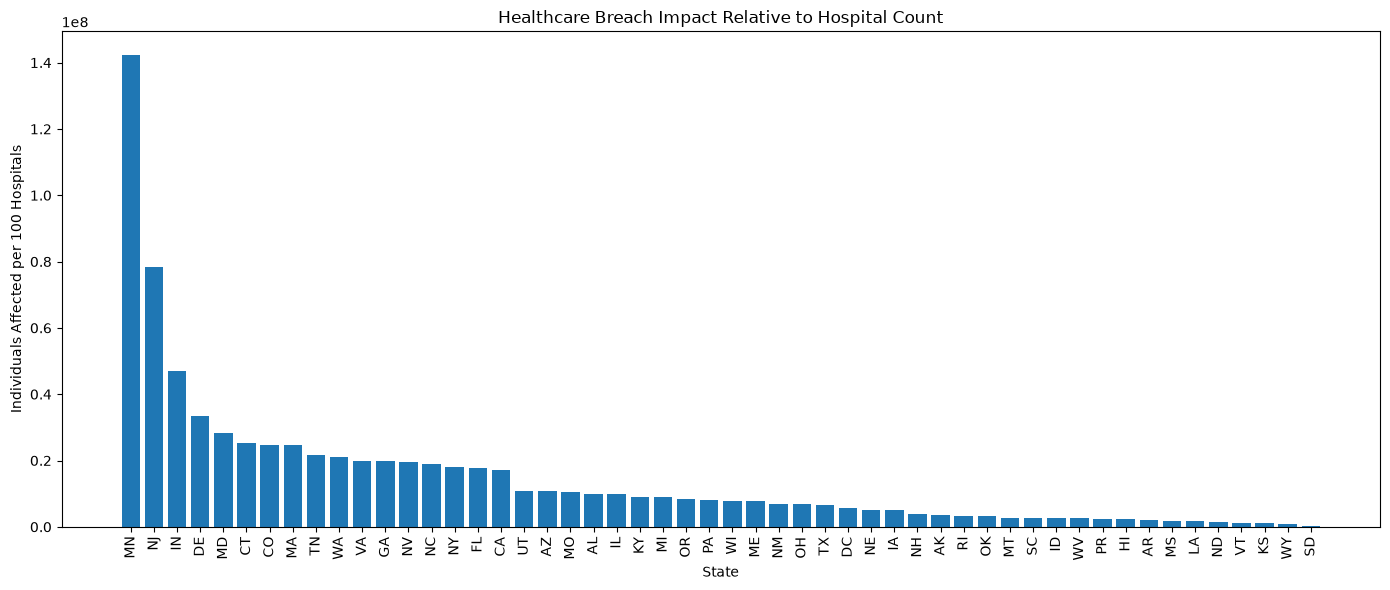

In [139]:
plt.figure(figsize=(14, 6))

plot_data = state_analysis.sort_values(
    "affected_per_100_hospitals",
    ascending=False
)

plt.bar(
    plot_data["state"],
    plot_data["affected_per_100_hospitals"]
)

plt.xlabel("State")
plt.ylabel("Individuals Affected per 100 Hospitals")
plt.title("Healthcare Breach Impact Relative to Hospital Count")

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [140]:


hospital_features = [
    "provider_ccn",
    "state_code",
    "fiscal_year",
    "number_of_beds",
    "fte_employees_on_payroll",
    "total_assets",
    "cash_on_hand_and_in_banks",
    "total_liabilities",
    "net_income",
    "total_costs",
    "total_patient_revenue",
    "total_income",
    "rural_versus_urban",
    "type_of_control"
]

hospital_data = historical_financials[hospital_features].copy()


hospital_data = hospital_data.dropna(
    subset=["provider_ccn", "state_code", "fiscal_year"]
)


print(
    hospital_data.duplicated(
        subset=["provider_ccn", "fiscal_year"]
    ).sum()
)

1319


In [141]:
hospital_by_state_year = (
    hospital_data
    .groupby(["state_code", "fiscal_year"])
    .agg(
        hospital_count=("provider_ccn", "nunique"),
        avg_beds=("number_of_beds", "mean"),
        avg_employees=("fte_employees_on_payroll", "mean"),
        avg_assets=("total_assets", "mean"),
        avg_cash=("cash_on_hand_and_in_banks", "mean"),
        avg_liabilities=("total_liabilities", "mean"),
        avg_net_income=("net_income", "mean"),
        avg_total_costs=("total_costs", "mean"),
        avg_patient_revenue=("total_patient_revenue", "mean"),
        avg_total_income=("total_income", "mean")
    )
    .reset_index()
)

display(hospital_by_state_year.head())

,state_code,fiscal_year,hospital_count,avg_beds,avg_employees,avg_assets,avg_cash,avg_liabilities,avg_net_income,avg_total_costs,avg_patient_revenue,avg_total_income
0,AK,2011,21,60.619048,444.650000,1.050154e+08,6.698498e+06,1.542877e+07,5.594928e+06,6.795407e+07,1.980032e+08,5.850485e+06
1,AK,2012,25,56.434783,683.697273,1.127344e+08,6.886012e+06,9.226206e+06,1.445359e+06,6.716788e+07,2.124835e+08,1.653628e+06
2,AK,2013,25,58.120000,438.831304,1.179949e+08,6.367044e+06,4.735227e+06,-2.079927e+07,7.614619e+07,2.232249e+08,-2.089450e+07
3,AK,2014,25,58.160000,504.635000,1.318532e+08,7.685912e+06,1.256010e+07,-2.140114e+07,7.790555e+07,2.419934e+08,-2.171870e+07
4,AK,2015,24,56.583333,558.235417,1.426408e+08,7.293065e+06,2.140128e+07,-2.553380e+07,8.425660e+07,2.740342e+08,-2.491898e+07


In [142]:
breach_by_state_year = (
    breaches
    .groupby(["state", "breach_year"])
    .agg(
        total_breaches=("individuals_affected", "size"),
        total_individuals_affected=("individuals_affected", "sum")
    )
    .reset_index()
)

In [143]:

hospital_by_state_year["state"] = (
    hospital_by_state_year["state_code"].str.upper().str.strip()
)

breach_by_state_year["state"] = (
    breach_by_state_year["state"].str.upper().str.strip()
)


hospital_by_state_year["year"] = pd.to_numeric(
    hospital_by_state_year["fiscal_year"], errors="coerce"
)

breach_by_state_year["year"] = pd.to_numeric(
    breach_by_state_year["breach_year"], errors="coerce"
)

model_data = hospital_by_state_year.merge(
    breach_by_state_year,
    on=["state", "year"],
    how="inner"
)


model_data["log_affected"] = np.log1p(
    model_data["total_individuals_affected"]
)

display(model_data.head())
print("Final dataset shape:", model_data.shape)

,state_code,fiscal_year,hospital_count,avg_beds,avg_employees,avg_assets,avg_cash,avg_liabilities,avg_net_income,avg_total_costs,avg_patient_revenue,avg_total_income,state,year,breach_year,total_breaches,total_individuals_affected,log_affected
0,AK,2011,21,60.619048,444.650000,1.050154e+08,6.698498e+06,1.542877e+07,5.594928e+06,6.795407e+07,1.980032e+08,5.850485e+06,AK,2011,2011,2,2266.0,7.726213
1,AK,2012,25,56.434783,683.697273,1.127344e+08,6.886012e+06,9.226206e+06,1.445359e+06,6.716788e+07,2.124835e+08,1.653628e+06,AK,2012,2012,1,2743.0,7.917172
2,AK,2013,25,58.120000,438.831304,1.179949e+08,6.367044e+06,4.735227e+06,-2.079927e+07,7.614619e+07,2.232249e+08,-2.089450e+07,AK,2013,2013,1,1556.0,7.350516
3,AK,2015,24,56.583333,558.235417,1.426408e+08,7.293065e+06,2.140128e+07,-2.553380e+07,8.425660e+07,2.740342e+08,-2.491898e+07,AK,2015,2015,1,553.0,6.317165
4,AK,2016,26,94.400000,609.028000,1.575677e+08,1.081105e+07,2.666530e+07,-2.584763e+07,8.666699e+07,3.056889e+08,-2.527808e+07,AK,2016,2016,1,14719.0,9.596962


Final dataset shape: (654, 18)


In [144]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.dummy import DummyRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [145]:
hospital_features = [
    "provider_ccn",
    "state_code",
    "fiscal_year",
    "number_of_beds",
    "fte_employees_on_payroll",
    "total_assets",
    "cash_on_hand_and_in_banks",
    "total_liabilities",
    "net_income",
    "total_costs",
    "total_patient_revenue",
    "total_income"
]

hospital_data = historical_financials[hospital_features].copy()

hospital_data = hospital_data.dropna(
    subset=["provider_ccn", "state_code", "fiscal_year"]
)


duplicates = hospital_data.duplicated(
    subset=["provider_ccn", "fiscal_year"]
).sum()

print("Duplicate hospital-year records:", duplicates)

Duplicate hospital-year records: 1319


In [146]:
hospital_by_state_year = (
    hospital_data
    .groupby(["state_code", "fiscal_year"])
    .agg(
        hospital_count=("provider_ccn", "nunique"),
        avg_beds=("number_of_beds", "mean"),
        avg_employees=("fte_employees_on_payroll", "mean"),
        avg_assets=("total_assets", "mean"),
        avg_cash=("cash_on_hand_and_in_banks", "mean"),
        avg_liabilities=("total_liabilities", "mean"),
        avg_net_income=("net_income", "mean"),
        avg_total_costs=("total_costs", "mean"),
        avg_patient_revenue=("total_patient_revenue", "mean"),
        avg_total_income=("total_income", "mean")
    )
    .reset_index()
)

hospital_by_state_year = hospital_by_state_year.rename(
    columns={"state_code": "state"}
)

display(hospital_by_state_year.head())

,state,fiscal_year,hospital_count,avg_beds,avg_employees,avg_assets,avg_cash,avg_liabilities,avg_net_income,avg_total_costs,avg_patient_revenue,avg_total_income
0,AK,2011,21,60.619048,444.650000,1.050154e+08,6.698498e+06,1.542877e+07,5.594928e+06,6.795407e+07,1.980032e+08,5.850485e+06
1,AK,2012,25,56.434783,683.697273,1.127344e+08,6.886012e+06,9.226206e+06,1.445359e+06,6.716788e+07,2.124835e+08,1.653628e+06
2,AK,2013,25,58.120000,438.831304,1.179949e+08,6.367044e+06,4.735227e+06,-2.079927e+07,7.614619e+07,2.232249e+08,-2.089450e+07
3,AK,2014,25,58.160000,504.635000,1.318532e+08,7.685912e+06,1.256010e+07,-2.140114e+07,7.790555e+07,2.419934e+08,-2.171870e+07
4,AK,2015,24,56.583333,558.235417,1.426408e+08,7.293065e+06,2.140128e+07,-2.553380e+07,8.425660e+07,2.740342e+08,-2.491898e+07


In [147]:
breach_by_state_year = (
    breaches
    .groupby(["state", "breach_year"])
    .agg(
        total_breaches=("individuals_affected", "count"),
        total_individuals_affected=("individuals_affected", "sum")
    )
    .reset_index()
)

display(breach_by_state_year.head())

,state,breach_year,total_breaches,total_individuals_affected
0,AK,2009,1,501.0
1,AK,2010,1,2000.0
2,AK,2011,2,2266.0
3,AK,2012,1,2743.0
4,AK,2013,1,1556.0


In [148]:

hospital_by_state_year["state"] = (
    hospital_by_state_year["state"].str.upper().str.strip()
)

breach_by_state_year["state"] = (
    breach_by_state_year["state"].str.upper().str.strip()
)


hospital_by_state_year["year"] = pd.to_numeric(
    hospital_by_state_year["fiscal_year"], errors="coerce"
)

breach_by_state_year["year"] = pd.to_numeric(
    breach_by_state_year["breach_year"], errors="coerce"
)


model_data = hospital_by_state_year.merge(
    breach_by_state_year,
    on=["state", "year"],
    how="left"
)


model_data["total_breaches"] = (
    model_data["total_breaches"].fillna(0)
)

model_data["total_individuals_affected"] = (
    model_data["total_individuals_affected"].fillna(0)
)


model_data["log_affected"] = np.log1p(
    model_data["total_individuals_affected"]
)

display(model_data.head())

print("Modeling dataset shape:", model_data.shape)
print("Number of states:", model_data["state"].nunique())
print("Years:", sorted(model_data["year"].dropna().unique()))

,state,fiscal_year,hospital_count,avg_beds,avg_employees,avg_assets,avg_cash,avg_liabilities,avg_net_income,avg_total_costs,avg_patient_revenue,avg_total_income,year,breach_year,total_breaches,total_individuals_affected,log_affected
0,AK,2011,21,60.619048,444.650000,1.050154e+08,6.698498e+06,1.542877e+07,5.594928e+06,6.795407e+07,1.980032e+08,5.850485e+06,2011,2011.0,2.0,2266.0,7.726213
1,AK,2012,25,56.434783,683.697273,1.127344e+08,6.886012e+06,9.226206e+06,1.445359e+06,6.716788e+07,2.124835e+08,1.653628e+06,2012,2012.0,1.0,2743.0,7.917172
2,AK,2013,25,58.120000,438.831304,1.179949e+08,6.367044e+06,4.735227e+06,-2.079927e+07,7.614619e+07,2.232249e+08,-2.089450e+07,2013,2013.0,1.0,1556.0,7.350516
3,AK,2014,25,58.160000,504.635000,1.318532e+08,7.685912e+06,1.256010e+07,-2.140114e+07,7.790555e+07,2.419934e+08,-2.171870e+07,2014,NaN,0.0,0.0,0.000000
4,AK,2015,24,56.583333,558.235417,1.426408e+08,7.293065e+06,2.140128e+07,-2.553380e+07,8.425660e+07,2.740342e+08,-2.491898e+07,2015,2015.0,1.0,553.0,6.317165


Modeling dataset shape: (769, 17)
Number of states: 56
Years: [np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]


In [149]:
features = [
    "hospital_count",
    "avg_beds",
    "avg_employees",
    "avg_assets",
    "avg_cash",
    "avg_liabilities",
    "avg_net_income",
    "avg_total_costs",
    "avg_patient_revenue",
    "avg_total_income"
]

X = model_data[features]


y = model_data["log_affected"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (769, 10)
y shape: (769,)


In [150]:

test_year = model_data["year"].max()


train_mask = model_data["year"] < test_year


test_mask = model_data["year"] == test_year

X_train = X.loc[train_mask]
X_test = X.loc[test_mask]

y_train = y.loc[train_mask]
y_test = y.loc[test_mask]

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))
print("Testing year:", test_year)

Training observations: 714
Testing observations: 55
Testing year: 2024


In [151]:
models = {
    "Baseline": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DummyRegressor(strategy="mean"))
    ]),

    "Linear Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),

    "Ridge Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=10))
    ]),

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestRegressor(
            n_estimators=300,
            max_depth=5,
            min_samples_leaf=3,
            random_state=42
        ))
    ]),

    "Gradient Boosting": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", GradientBoostingRegressor(
            n_estimators=100,
            learning_rate=0.05,
            max_depth=2,
            random_state=42
        ))
    ])
}

In [152]:
results = []

for name, model in models.items():

   
    model.fit(X_train, y_train)

    
    predictions = model.predict(X_test)

    
    mae = mean_absolute_error(y_test, predictions)

    rmse = np.sqrt(mean_squared_error(y_test, predictions))

    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })


results_df = pd.DataFrame(results)

display(
    results_df.sort_values("RMSE")
)

,Model,MAE,RMSE,R2
3,Random Forest,2.029053,2.783563,0.649784
4,Gradient Boosting,2.136140,2.898158,0.620355
2,Ridge Regression,3.077497,3.855284,0.328189
1,Linear Regression,3.091813,3.872842,0.322056
0,Baseline,4.497883,5.168111,-0.207252


In [153]:
gb_model = models["Gradient Boosting"]

gb_importance = pd.DataFrame({
    "Feature": features,
    "Importance": gb_model.named_steps["model"].feature_importances_
})

gb_importance = gb_importance.sort_values(
    "Importance", ascending=False
)

display(gb_importance)

,Feature,Importance
0,hospital_count,0.550129
8,avg_patient_revenue,0.296845
3,avg_assets,0.042091
4,avg_cash,0.034559
7,avg_total_costs,0.028624
1,avg_beds,0.015995
2,avg_employees,0.009664
5,avg_liabilities,0.009466
6,avg_net_income,0.006806
9,avg_total_income,0.005821


In [154]:
from sklearn.inspection import permutation_importance

perm_results = permutation_importance(
    gb_model,
    X_test,
    y_test,
    n_repeats=30,
    random_state=42,
    scoring="r2",
    n_jobs=-1
)

permutation_df = pd.DataFrame({
    "Feature": features,
    "Importance": perm_results.importances_mean,
    "Std": perm_results.importances_std
})

permutation_df = permutation_df.sort_values(
    "Importance",
    ascending=False
)

display(permutation_df)

,Feature,Importance,Std
0,hospital_count,0.608640,0.116654
8,avg_patient_revenue,0.161137,0.057054
7,avg_total_costs,0.026319,0.010212
3,avg_assets,0.009725,0.008397
4,avg_cash,0.007903,0.013307
6,avg_net_income,0.007003,0.008387
1,avg_beds,0.005243,0.001825
5,avg_liabilities,0.004847,0.002181
2,avg_employees,0.004568,0.003708
9,avg_total_income,0.001973,0.009745
